# Download and prepare `PPFD_IN` (2004-2026.09)

**notebook version**: `6` (22 Oct 2026)

## ℹ️ About this notebook

Downloads screened photosynthetic photon flux density `PPFD_IN` from InfluxDB, merges the sources,
applies the 2012 corrections and the nighttime zero-offset, gap-fills, and writes the product to
the external data folder. The structure follows notebooks `01` (`SW_IN`) and `02` (`TA`); the
gap-filling differences are in *Method*. A separate section establishes **which instrument the
exported column is**, because the fieldbook records a PAR sensor installed in January 2016 that is
not this one.

**Output columns**

- `PPFD_IN_T1_47_1_gfXG`: gap-filled series (µmol m⁻² s⁻¹, complete, non-negative)
- `FLAG_PPFD_IN_T1_47_1_ISFILLED`: `0` measured, `>0` filled (codes in `FLAG_LEGEND`)

**Run notebook `01` first**: its gap-filled `SW_IN` is a driver here.

***

## 📇 Data sources

- `PPFD_IN_T1_47_1`: ETH, 47 m, the product series; `mst` 2004-2021, `diive` 2022-2026.
  Measurements start on **2004-09-20**; earlier records are filled.
- Drivers (**there is no NABEL PPFD sensor**):
  - `SW_IN_T1_47_1_gfXG`: gap-filled `SW_IN` from notebook `01`, complete and nearly
    proportional to `PPFD_IN`.
  - `SW_IN_LAE_MS`: MeteoSwiss Lägern global radiation, 2.5 km away, from
    `10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb`. Independent of the tower, so it carries the
    real sky state where the tower `SW_IN` was gap-filled.
- `PPFD_IN_T1_47_2`: the **second** PAR sensor at 47 m, `mst` only (2016-2021). Neither driver nor
  output; used to identify the exported sensor.
- Beside the workflow folder: the GIN fieldbook export, and the CR10X (2004-2006) and CR1000
  (2016) logger programs, which state what each era measured and how it was converted.

Screening: `mst` is the deprecated MeteoScreeningTool, `diive` is diive; both screen ETH data.

## ⏱️ Timestamp convention

The database stores UTC `TIMESTAMP_END`. `InfluxIO` shifts it by `TIMEZONE_OFFSET_TO_UTC_HOURS` to
local time, and `TimestampSanitizer(output_middle_timestamp=True)` converts it to
`TIMESTAMP_MID`.

***

## ⚙️ Settings

### Data settings

In [1]:
DIRCONF = r'F:\dev\poet\configs'  # database connection configs
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # local time UTC+01:00 (CET)
REQUIRED_TIME_RESOLUTION = '30min'  # TimestampSanitizer raises if the data disagree
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389  # CH-LAE
NIGHTTIME_THRESHOLD = 0.001  # SW_IN_POT below this counts as night, as in notebook 01

TARGET = "PPFD_IN_T1_47_1"

# Last record (TIMESTAMP_MID). The file names say 2026.09; the export check asserts it.
PERIOD_END = '2026-09-30 23:45:00'
# 2026 ends in September, so statistics that compare calendar years use full years only.
LAST_FULL_YEAR = 2025

# Output, in the external data folder, same numeric prefix as this notebook
OUTNAME = "03_METEO_PPFD_IN_GAPFILLED_2004-2026.09"
OUTPATH = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"

# Gap-filled SW_IN from notebook 01, used as a driver
SWIN_FILE = "01_METEO_SW_IN_GAPFILLED_2004-2026.09"
SWIN_COL = "SW_IN_T1_47_1_gfXG"
SWIN_FLAG = "FLAG_SW_IN_T1_47_1_ISFILLED"

# Reference: MeteoSwiss Lägern global radiation, an independent second driver, written by
# 10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb
REFPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet")
REFCOL = "SW_IN_LAE_MS"

# --- Inputs for the sensor-identity section ----------------------------------------------------
# The second PAR sensor at 47 m: neither driver nor output, used only to tell the two apart
SECOND_SENSOR = "PPFD_IN_T1_47_2"

# Site maintenance record (GIN export), stored beside the workflow folder
FIELDBOOK = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\fieldbook_gin\CH-LAE-laegeren-export_20261022.csv")

# Every surviving logger program that measures incoming PAR at 47 m, read so that the sensor
# identity and the conversion are re-derived on every run. PROGRAMS_BF2: the five CR10X programs
# with the Delta-T sensor. PROGRAM_BEFORE_BF2: the one before them, which writes a different probe
# to the same storage location. PROGRAM_AFTER: the CR1000 program of the January 2016 changeover.
_CSI = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
        r"\csi_loggerscripts")
PROGRAMS_BF2 = [_CSI + r"\LAEGEREN.20040810.CSI",
                _CSI + r"\LAEGEREN.20041228.CSI",
                _CSI + r"\LAEGEREN.20050818.CSI",
                _CSI + r"\LAEGEREN.20050914.CSI",
                _CSI + r"\LAEGEREN.20060524.csi"]
PROGRAM_BEFORE_BF2 = _CSI + r"\LAEGEREN.20040526.CSI"
PROGRAM_AFTER = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
                 r"\logger_scripts\ch-lae_idl_t1_47_1-Version_20160118\CH-LAE_iDL_T1_47_1.CR1")

### Imports

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import html
import re
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme('notebook')

import diive as dv
from diive.core.io.db.influx import InfluxIO
from diive.core.times.times import TimestampSanitizer

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-23 12:37:38
diive version: v0.93.0


In [3]:
# 0/1/2 are the standard diive gap-filling flags. 3 marks nighttime records set to zero by
# physics and 4 short gaps filled by interpolation, matching the codes used in notebooks 01/02.
FLAG_LEGEND = {
    0: '0 = observed',
    1: '1 = gap-filled by the XGBoost model',
    2: '2 = gap-filled by the timestamp-only fallback model (a driver was missing)',
    3: '3 = nighttime gap, set to zero by physics',
    4: '4 = gap-filled by linear interpolation (short gap)',
}

### Captions

In [4]:
# Caption helpers for every table and figure. Defined above their first use.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # A layout engine that still runs at draw time makes room for the caption itself.
    # plt.tight_layout() runs once and leaves a PlaceHolderLayoutEngine, so a supxlabel caption
    # would overlap the tick labels; those figures take the manual branch below. Notebooks 01,
    # 02, 99 and the overview carry an earlier version that tests only for None; copy this one.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')

### Plot helpers

In [5]:
# Diagnostic plots for the gap-filling run. Each helper builds its own caption from its
# arguments and data, so every call site gets a caption that matches it (as in notebooks 01, 99).

def plot_gapfill_panels(gapfilled, flag, label, ylabel=r'$\mathrm{\mu mol\ m^{-2}\ s^{-1}}$',
                        figsize=(16, 7)):
    """Three stacked panels: measured only, the final series, and the fills alone.

    The third panel shows the fills against a blank background, so a fill at the wrong level or a
    block of fills where none belong is visible.
    """
    _plotdf = pd.DataFrame({
        'observed': gapfilled.where(flag == 0),
        'gapfilled': gapfilled,
        'gap values': gapfilled.where(flag > 0),
    })
    axs = _plotdf.plot(subplots=True, figsize=figsize, x_compat=True, alpha=.9,
                       title=f"{label}: measured, gap-filled, fills only", legend=True)
    for ax in axs:
        ax.set_ylabel(ylabel)
    plt.tight_layout()
    fig = axs[0].get_figure()
    _blocks = int(((flag > 0) & ~(flag > 0).shift(1, fill_value=False)).sum())
    figcap(fig, f"{label}. Top: measured records only. Middle: the exported series. Bottom: the "
                f"{int((flag > 0).sum()):,} filled records ({100 * (flag > 0).mean():.1f} % of the "
                f"record) alone, where a fill at an implausible level stands out. They fall in "
                f"{_blocks:,} runs. Most runs are isolated half-hours, but most filled records "
                f"sit in a few long blocks, the pre-record period of 2004 and a few outages, so "
                f"filtering on the flag removes mainly whole periods.")
    return fig


def plot_pred_vs_measured(model, label, unit=r'$\mathrm{\mu mol\ m^{-2}\ s^{-1}}$'):
    """Predicted against measured on the held-out test set, plus residuals.

    `gapfilled` equals the measurement wherever the flag is 0, so only the held-out test records
    validate the fills.
    """
    test = model.traintest_details_['test_df']
    measured = test[model.target_col].values
    predicted = model.model_.predict(test.drop(columns=model.target_col))
    residual = predicted - measured
    rmse = float(np.sqrt((residual ** 2).mean()))
    bias = float(residual.mean())
    # Half the records are nighttime zeros, which any model predicts exactly, so the daylight
    # RMSE is the error to judge a fill by. Both are reported.
    _day = measured > 20
    rmse_day = float(np.sqrt((residual[_day] ** 2).mean()))

    fig, axs = plt.subplots(ncols=2, figsize=(13, 5.5), dpi=100, layout='constrained')
    fig.suptitle(f"{label}  (held-out test set, n={len(test):,})", fontsize=13)
    axs[0].hexbin(measured, predicted, gridsize=60, mincnt=1, bins='log', cmap='viridis')
    lim = [float(min(measured.min(), predicted.min())), float(max(measured.max(), predicted.max()))]
    axs[0].plot(lim, lim, 'r-', lw=1.2, label='1:1')
    axs[0].set_xlabel(f'measured {unit}')
    axs[0].set_ylabel(f'predicted {unit}')
    axs[0].set_title(f'RMSE {rmse:.2f}   bias {bias:+.2f}', fontsize=11)
    axs[0].legend(fontsize=8)
    axs[1].hexbin(predicted, residual, gridsize=60, mincnt=1, bins='log', cmap='viridis')
    axs[1].axhline(0, color='r', lw=1.2)
    axs[1].set_xlabel(f'predicted {unit}')
    axs[1].set_ylabel(f'residual (predicted - measured) {unit}')
    axs[1].set_title('Residuals', fontsize=11)
    figcap(fig, f"the {label} on the {len(test):,} records held out of training. Left: "
                f"predicted against measured with the 1:1 line. Over all held-out records the "
                f"RMSE is {rmse:.0f} umol m-2 s-1 and the bias {bias:+.1f}, but half of them are "
                f"nighttime zeros; over the {int(_day.sum()):,} daylight records alone the RMSE is "
                f"{rmse_day:.0f} umol m-2 s-1, the number to judge a fill by. Right: residual "
                f"against prediction. The spread widens away from zero and then stays broadly "
                f"constant, with outliers at every level, most likely half-hours of broken cloud "
                f"in which the sensor and its drivers see different light.")
    return fig


def plot_feature_importances(results, label, top=12):
    """The drivers the model used, as a bar chart.

    A model that leans mainly on the timestamp features fills with climatology, whatever its scores.
    """
    imp = results.feature_importances.copy()
    _col = next((c for c in ('PERM_IMPORTANCE', 'IMPORTANCE', 'importance')
                 if c in imp.columns), imp.columns[0])
    imp = imp.sort_values(_col, ascending=False).head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(imp) + 1.6), dpi=100, layout='constrained')
    ax.barh(imp.index.astype(str), imp[_col], color='#1565C0')
    ax.set_xlabel(_col)
    ax.set_title(f'Driver importance: {label}', fontsize=12)
    ax.grid(axis='x', alpha=0.3)
    figcap(fig, f"the {min(top, len(imp))} most important drivers of the {label}, ranked by "
                f"{_col}; the strongest is {str(imp.index[-1])}. A model led by the timestamp "
                f"features would fill with climatology.")
    return fig


def fill_stats_by_year(flag, label, legend=None):
    """Records per year and flag, plus a stacked bar chart of the filled ones."""
    legend = legend or FLAG_LEGEND
    tab = (pd.crosstab(flag.index.year, flag)
             .rename(columns=lambda f: legend.get(f, f))
             .rename_axis(index='year', columns=None))
    filled = tab.drop(columns=[c for c in tab.columns if str(c).startswith('0 =')], errors='ignore')
    if not filled.empty and filled.to_numpy().sum() > 0:
        ax = filled.plot(kind='bar', stacked=True, figsize=(14, 4),
                         title='Filled records per year')
        ax.set_ylabel('records')
        ax.legend(fontsize=8)
        plt.tight_layout()
        _worst = filled.sum(axis=1).idxmax()
        _totals = filled.sum(axis=1)
        _quiet = int((_totals < 100).sum())
        _none = int((_totals == 0).sum())
        _first = flag.index[flag == 0][0]
        _pre = int(((flag.index < _first) & (flag.index.year == _worst)).sum())
        figcap(ax.get_figure(),
               f"filled records per year and method for {label}. The most filled year is {_worst} "
               f"({int(_totals.max()):,} records, {_pre:,} of them before the first measured "
               f"record); {_quiet} of {len(_totals)} years have fewer than 100 filled records and "
               f"{_none} have none.")
    # Counts only, so a partial last year is kept and labelled rather than dropped
    _partial = (f"; {tab.index.max()} is a partial year (January to "
                f"{pd.Timestamp(PERIOD_END):%B})" if tab.index.max() > LAST_FULL_YEAR else "")
    tabcap(f"records per year and provenance code for {label}; each row sums to the half-hours "
           f"of that year{_partial}")
    return tab


def plot_fill_overview(series, flag, label, ylabel=r'$\mathrm{\mu mol\ m^{-2}\ s^{-1}}$'):
    """Three panels on the final series: where the fills are and whether they behave.

    The flag over date and time of day; monthly means of the full and the measured-only series (a
    systematic gap means biased fills); the share of filled records per month.
    """
    fig = plt.figure(figsize=(18, 9), dpi=100, layout='constrained')
    gs = gridspec.GridSpec(2, 2, figure=fig)
    fig.suptitle(f'Gap-filling overview: {label}', fontsize=15)

    ax = fig.add_subplot(gs[:, 0])
    dv.plotting.HeatmapDateTime(series=flag.astype(float)).plot(
        ax=ax, cb_digits_after_comma=0, zlabel='flag',
        format_style=dv.plotting.FormatStyle(title='Flag (0 = measured)', title_fontsize=11))

    measured = series.where(flag == 0)
    ax = fig.add_subplot(gs[0, 1])
    series.resample('MS').mean().plot(ax=ax, label='all records', lw=1.2)
    measured.resample('MS').mean().plot(ax=ax, label='measured only', lw=1.2, ls='--')
    ax.set_title('Monthly means', fontsize=11)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

    ax = fig.add_subplot(gs[1, 1])
    share = (flag > 0).resample('MS').mean() * 100
    ax.fill_between(share.index, share.values, step='mid', alpha=.7)
    ax.set_title('Share of filled records per month', fontsize=11)
    ax.set_ylabel('%')

    _monthly_gap = (series.resample('MS').mean() - measured.resample('MS').mean()).abs()
    _gap = _monthly_gap.max()
    _gap_month = _monthly_gap.idxmax()
    _rest = _monthly_gap.drop(index=_monthly_gap.index[_monthly_gap.index.year
                                                       == _gap_month.year]).max()
    figcap(fig, f"fills of {label}. Left: provenance code by date and time of day. The one "
                f"extended block, at the foot of the panel, is the period before measurements "
                f"begin (zero code at night, model code by day); above it everything is measured "
                f"apart from a few horizontal lines, each an outage of a few days. Top right: "
                f"monthly means of the complete series and of measured records only, "
                f"{_gap:.0f} umol m-2 s-1 apart in {_gap_month:%b %Y} and at most {_rest:.0f} in "
                f"any month outside that year. Bottom right: share of each month that is filled.")
    return fig

### 🔌 Connect to database

In [6]:
dbc = InfluxIO(dirconf=DIRCONF)

> Reading configuration files was successful.

v Connection to database works.

***

## ⬇️ Download

`mst` covers 2004-2021 and `diive` 2022 to September 2026. They do not overlap.

In [7]:
%%time

BUCKET = 'ch-lae_processed'
MEASUREMENTS = ['PPFD']

mst_ppfd, _, _ = dbc.download(
    bucket=BUCKET, measurements=MEASUREMENTS, fields=[TARGET],
    start='2004-01-01 00:00:01', stop='2022-01-01 00:00:01',
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version='meteoscreening_mst')

diive_ppfd, _, _ = dbc.download(
    bucket=BUCKET, measurements=MEASUREMENTS, fields=[TARGET],
    start='2022-01-01 00:00:01', stop='2026-10-01 00:00:01',  # includes the record ending 1 Oct 00:00
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version='meteoscreening_diive')

mst_ppfd = TimestampSanitizer(data=mst_ppfd, output_middle_timestamp=True,
                              nominal_freq=REQUIRED_TIME_RESOLUTION).get()
diive_ppfd = TimestampSanitizer(data=diive_ppfd, output_middle_timestamp=True,
                                nominal_freq=REQUIRED_TIME_RESOLUTION).get()
print(f"mst:   {mst_ppfd[TARGET].notna().sum():,} records")
print(f"diive: {diive_ppfd[TARGET].notna().sum():,} records")

> DOWNLOADING from bucket ch-lae_processed: variables ['PPFD_IN_T1_47_1'] from measurements 
['PPFD'], data version ['meteoscreening_mst'], between 2004-01-01 00:00:01 and 2022-01-01 00:00:01 
(timezone offset to UTC 1)

> Downloaded data for 1 variables:

> <-- PPFD_IN_T1_47_1: 300,291 records from 2004-09-20 11:00:00 to 2022-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

> DOWNLOADING from bucket ch-lae_processed: variables ['PPFD_IN_T1_47_1'] from measurements 
['PPFD'], data version ['meteoscreening_diive'], between 2022-01-01 00:00:01 and 2026-10-01 00:00:01
(timezone offset to UTC 1)

> Downloaded data for 1 variables:

> <-- PPFD_IN_T1_47_1: 83,150 records from 2022-01-01 00:30:00 to 2026-10-01 00:00:00, time 
resolution 30min (freq tag: 30min)

mst:   300,291 records
diive: 83,150 records
CPU times: total: 7.27 s
Wall time: 13.9 s


### Merge onto one continuous 30MIN index

#### 📋 Table: merged series on one 30MIN index

In [8]:
full_index = pd.date_range('2004-01-01 00:15:00', PERIOD_END, freq='30min',
                           name='TIMESTAMP_MIDDLE')
ppfd_2004_2026 = pd.DataFrame(index=full_index)
ppfd_2004_2026[TARGET] = (mst_ppfd[TARGET]
                          .combine_first(diive_ppfd[TARGET])
                          .reindex(full_index))
print(f"{TARGET}: {ppfd_2004_2026[TARGET].notna().sum():,} of {len(ppfd_2004_2026):,} records")
print(f"first measurement: {ppfd_2004_2026[TARGET].first_valid_index()}")
tabcap("the merged series on one continuous 30MIN index. `mst` covers 2004-2021 and `diive` "
       "2022-2026; they do not overlap, so combine_first joins two screenings of one measurement "
       "and fills nothing")
ppfd_2004_2026

PPFD_IN_T1_47_1: 383,441 of 398,832 records
first measurement: 2004-09-20 10:45:00
Table - the merged series on one continuous 30MIN index. `mst` covers 2004-2021 and `diive`
2022-2026; they do not overlap, so combine_first joins two screenings of one measurement and fills
nothing



,PPFD_IN_T1_47_1
TIMESTAMP_MIDDLE,
2004-01-01 00:15:00,NaN
2004-01-01 00:45:00,NaN
2004-01-01 01:15:00,NaN
2004-01-01 01:45:00,NaN
2004-01-01 02:15:00,NaN
...,...
2026-09-30 21:45:00,0.0
2026-09-30 22:15:00,0.0
2026-09-30 22:45:00,0.0


### 📊 Plot: heatmap of the merged record

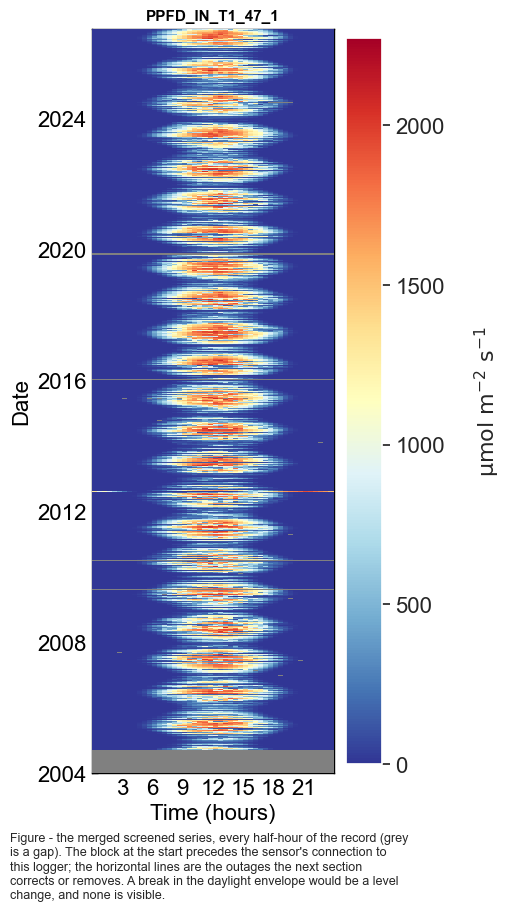

In [9]:
fig, ax = plt.subplots(figsize=(5, 9), dpi=100, layout="constrained")
dv.plotting.HeatmapDateTime(series=ppfd_2004_2026[TARGET]).plot(
    ax=ax, cb_digits_after_comma=0, zlabel=r'$\mathrm{\mu mol\ m^{-2}\ s^{-1}}$',
    format_style=dv.plotting.FormatStyle(title=TARGET, title_fontsize=11))
figcap(fig, "the merged screened series, every half-hour of the record (grey is a gap). The "
            "block at the start precedes the sensor's connection to this logger; the horizontal "
            "lines are the outages the next section corrects or removes. A break in the daylight "
            "envelope would be a level change, and none is visible.")

***

## ✴️ Corrections

### Timestamp shift in August 2012
**Info from fieldbook entry 17 Aug 2012:**
>   adjusted the logger date and time. On Servertime (Computer System Time) 17.08.2012 12:31.42 the loggertime was 16.08.2012 08:06:00. Synchronized time at 17.08.2012 11:40:00 servertime. The logger data aquisition on the moxa embedded was restarted

`PPFD_IN` shows the same `+15.5 h` shift as `SW_IN` and `TA` on 10-16 August and receives the
same correction.

#### 📊 Plot: the August 2012 clock shift, panel by panel

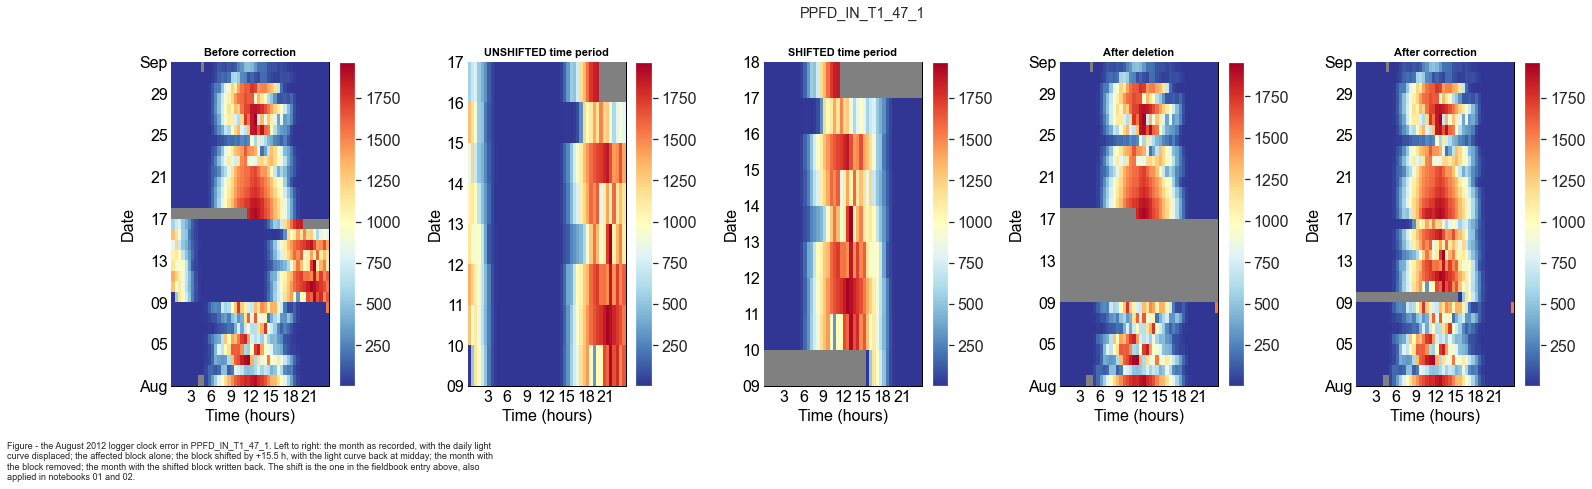

In [10]:
AFFECTED_VARS = [TARGET]
_df = ppfd_2004_2026.copy()

for av in AFFECTED_VARS:
    fig = plt.figure(figsize=(24, 6), dpi=72)
    fig.suptitle(f"{av}")
    gs = gridspec.GridSpec(1, 5)
    gs.update(wspace=0.5, hspace=1, left=.1, right=.9, top=.85, bottom=.1)
    ax_before, ax_unshifted, ax_shifted, ax_after, ax_corrected = [
        fig.add_subplot(gs[0, i]) for i in range(5)]

    _show_locs = (_df.index >= '2012-08-01 00:00') & (_df.index <= '2012-09-01 00:00')
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_before, cb_digits_after_comma=0, zlabel='',
        format_style=dv.plotting.FormatStyle(title="Before correction", title_fontsize=11))

    ISSUE_START = '2012-08-09 00:00'
    ISSUE_END = '2012-08-17 00:00'
    _shifted_locs = (_df.index >= ISSUE_START) & (_df.index <= ISSUE_END)
    _series_shifted = _df.loc[_shifted_locs, av].copy().dropna()
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_unshifted, cb_digits_after_comma=0, zlabel='',
        format_style=dv.plotting.FormatStyle(title="UNSHIFTED time period", title_fontsize=11))

    _series_shifted.index = _series_shifted.index + pd.Timedelta(hours=15.5)
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_shifted, cb_digits_after_comma=0, zlabel='',
        format_style=dv.plotting.FormatStyle(title="SHIFTED time period", title_fontsize=11))

    _overwrite_locs = (_df.index >= ISSUE_START) & (_df.index <= _series_shifted.index[-1])
    _df.loc[_overwrite_locs, av] = np.nan
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_after, cb_digits_after_comma=0, zlabel='',
        format_style=dv.plotting.FormatStyle(title="After deletion", title_fontsize=11))

    _df.loc[_overwrite_locs, av] = _series_shifted
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_corrected, cb_digits_after_comma=0, zlabel='',
        format_style=dv.plotting.FormatStyle(title="After correction", title_fontsize=11))
    figcap(fig, f"the August 2012 logger clock error in {av}. Left to right: the month as "
                f"recorded, with the daily light curve displaced; the affected block alone; the "
                f"block shifted by +15.5 h, with the light curve back at midday; the month with "
                f"the block removed; the month with the shifted block written back. The shift is "
                f"the one in the fieldbook entry above, also applied in notebooks 01 and 02.")

#### 📋 Table: series after the clock shift

In [11]:
ppfd_2004_2026 = _df.copy()
tabcap("the series after the August 2012 clock error has been shifted back onto the correct time axis")
ppfd_2004_2026

Table - the series after the August 2012 clock error has been shifted back onto the correct time
axis



,PPFD_IN_T1_47_1
TIMESTAMP_MIDDLE,
2004-01-01 00:15:00,NaN
2004-01-01 00:45:00,NaN
2004-01-01 01:15:00,NaN
2004-01-01 01:45:00,NaN
2004-01-01 02:15:00,NaN
...,...
2026-09-30 21:45:00,0.0
2026-09-30 22:15:00,0.0
2026-09-30 22:45:00,0.0


### Power failure and storm damage, 2012

The three windows removed in notebooks `01` and `02` apply here too. `PPFD_IN`, scaled to W m⁻²
equivalent and aligned day by day against NABEL `SW_IN` (the only site instrument not on the
affected logger):

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-07-28 | 0 | 49 | 49 |
| 2012-08-02 | 0 | 199 | 199 |
| 2012-08-09 | -32.5 h | 151 | 462 |
| **2012-08-11** | **+15.5 h** | **48** | 572 |
| **2012-08-16** | **+15.5 h** | **78** | 460 |
| 2012-08-18 | 0 | 34 | 34 |
| 2012-10-27 | 0 | 11 | 11 |
| 2012-10-30 | -24.0 h | 178 | 210 |
| 2012-11-05 | -24.0 h | 146 | 172 |
| 2012-11-11 | 0 | 6 | 6 |

The pattern matches `SW_IN` and `TA`: the `+15.5 h` clock offset on 10-16 August (corrected
above) and two unrepairable periods, 29 July to 9 August (tower power supply failure, repaired on
9 August) and late October to early November (storm damage, cable work on 6 November), as
recorded in the fieldbook. Notebooks `01` and `02` give the evidence. The windows, on the
**corrected** time axis, are the same as there.

#### 📊 Plot: 2012 after removing the damaged periods

Removed 1213 degraded records from PPFD_IN_T1_47_1 (gap-filled later).


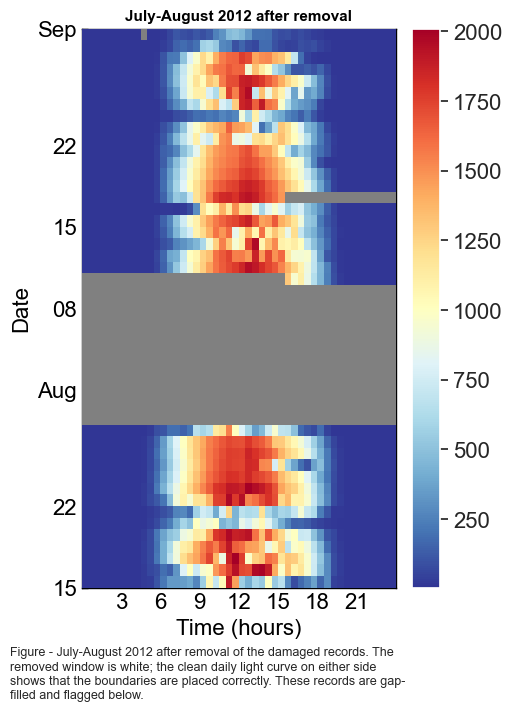

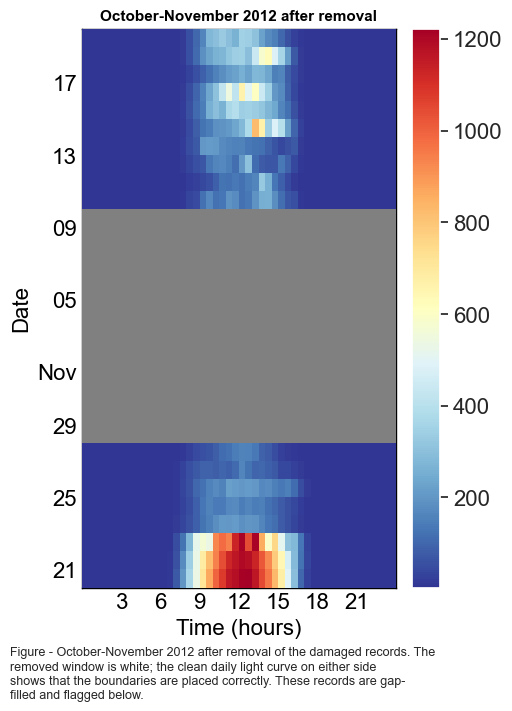

In [12]:
# Identical to notebooks 01 and 02: the faults are in the logger and the power supply, so every
# variable on that system is affected.
BAD_WINDOWS_2012 = [
    ('2012-07-29 00:00', '2012-08-10 15:30'),  # tower power supply failure (fieldbook 09.08.2012)
    ('2012-08-17 15:30', '2012-08-18 00:00'),  # transitional tail after the last shifted value
    ('2012-10-28 00:00', '2012-11-10 00:00'),  # storm damage, stressed cables (fieldbook 01./06.11.2012)
]

_before = int(ppfd_2004_2026[TARGET].notna().sum())
for _start, _end in BAD_WINDOWS_2012:
    _locs = (ppfd_2004_2026.index >= _start) & (ppfd_2004_2026.index <= _end)
    ppfd_2004_2026.loc[_locs, TARGET] = np.nan
_removed = _before - int(ppfd_2004_2026[TARGET].notna().sum())
print(f"Removed {_removed} degraded records from {TARGET} (gap-filled later).")

for _lo, _hi, _label in [('2012-07-15', '2012-09-01', 'July-August'),
                         ('2012-10-20', '2012-11-20', 'October-November')]:
    fig, ax = plt.subplots(figsize=(5, 7), dpi=100, layout="constrained")
    _show = (ppfd_2004_2026.index >= _lo) & (ppfd_2004_2026.index <= _hi)
    dv.plotting.HeatmapDateTime(series=ppfd_2004_2026.loc[_show, TARGET]).plot(
        ax=ax, cb_digits_after_comma=0, zlabel='',
        format_style=dv.plotting.FormatStyle(
            title=f'{_label} 2012 after removal', title_fontsize=11))
    figcap(fig, f"{_label} 2012 after removal of the damaged records. The removed window is "
                f"white; the clean daily light curve on either side shows that the boundaries are "
                f"placed correctly. These records are gap-filled and flagged below.")

### Nighttime zero-offset

`PPFD_IN` must read zero at night. `dv.corrections.remove_nighttime_zero_offset` subtracts each
day's mean nighttime value from that day, sets nighttime to zero and clamps negatives to zero. It
is the routine notebook `01` applies through `correct_nighttime_offset=True`, called directly
because `PPFD_IN` has no dedicated gap-filling class.

**The gap mask is taken first.** The correction also zeroes nighttime *gaps*, which would then be
exported as `0 = observed`. `PPFD_ORIGINAL_GAPS` is passed to the gap-filler, which flags them `3`.

#### 📊 Plot: nighttime offset correction, diive diagnostic

gaps before correction: 16,604


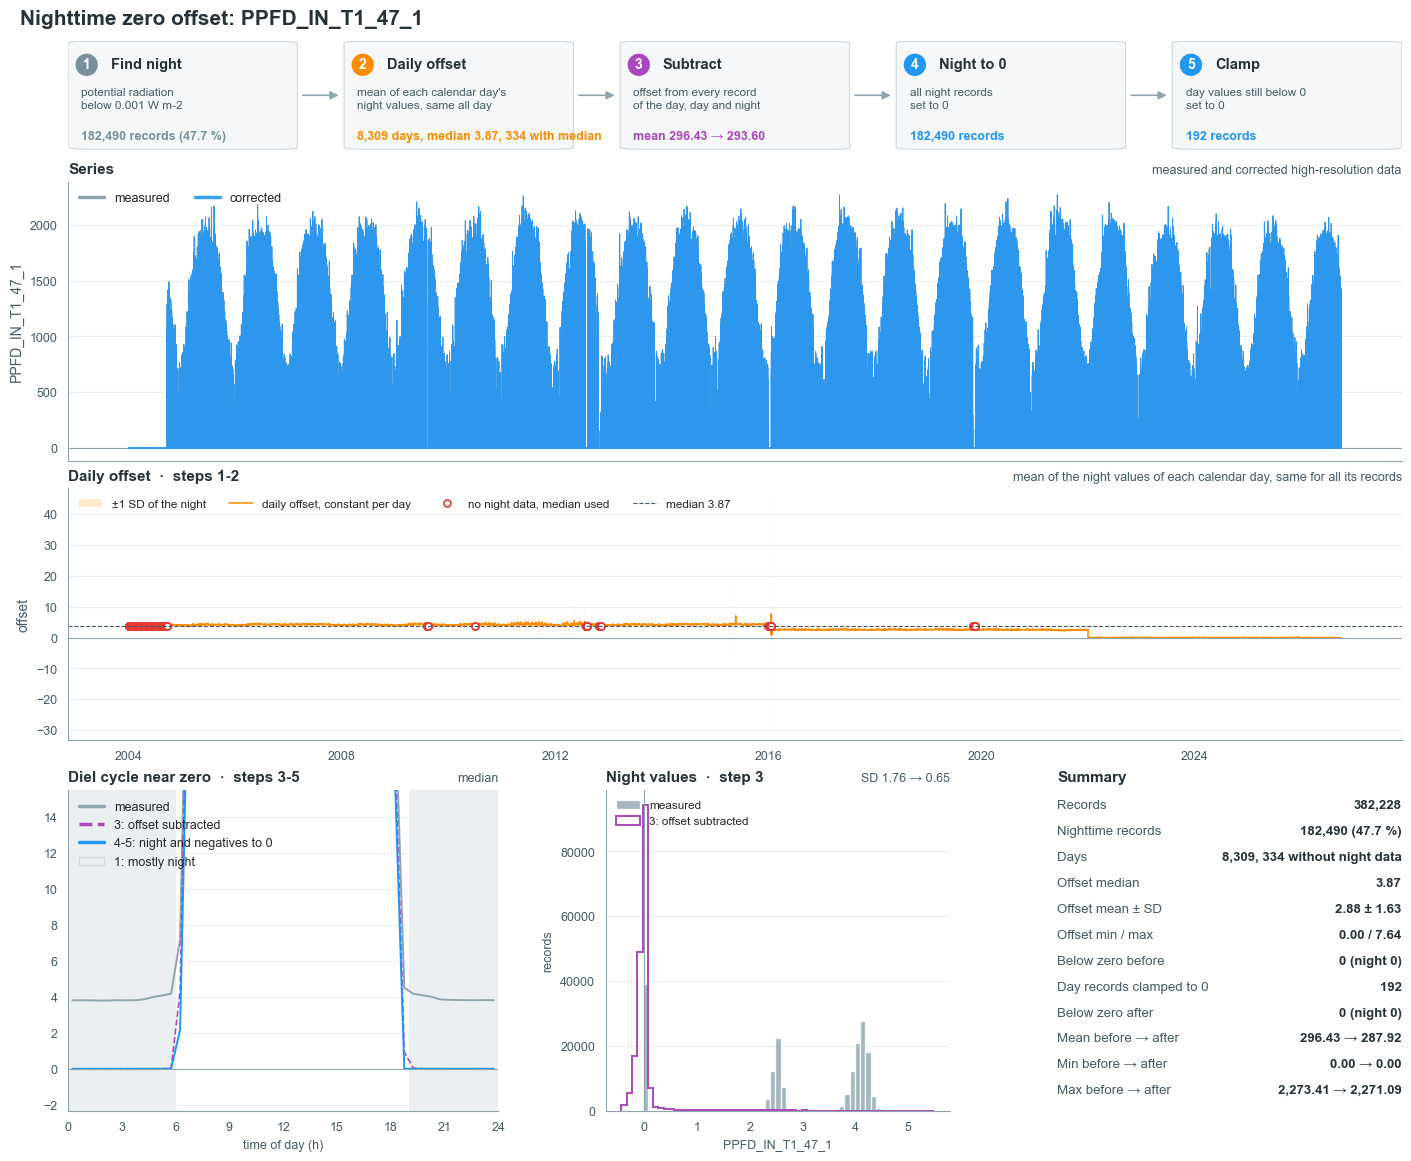

In [13]:
# Capture the gap mask BEFORE correcting: remove_nighttime_zero_offset() sets every nighttime
# record to zero, gaps included, which would otherwise be exported as 0 = observed.
PPFD_ORIGINAL_GAPS = ppfd_2004_2026[TARGET].isna()
print(f"gaps before correction: {int(PPFD_ORIGINAL_GAPS.sum()):,}")

ppfd_corrected = dv.corrections.remove_nighttime_zero_offset(
    series=ppfd_2004_2026[TARGET].copy(),
    lat=SITE_LAT, lon=SITE_LON, utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
    showplot=True, clamp_negatives=True,
)

#### 📋 Table: series after the offset correction

In [14]:
# Kept for the figure below; the assignment at the end of this cell overwrites it.
PPFD_BEFORE_OFFSET = ppfd_2004_2026[TARGET].copy()
_before = PPFD_BEFORE_OFFSET
print(f"before: min {_before.min():.2f}, records below zero: {(_before < 0).sum():,}")
print(f"after : min {ppfd_corrected.min():.2f}, records below zero: {(ppfd_corrected < 0).sum():,}")
print(f"mean change on measured records: {float((ppfd_corrected - _before).mean()):+.3f} umol m-2 s-1")
print(f"nighttime gaps zeroed by the correction: "
      f"{int((PPFD_ORIGINAL_GAPS & ppfd_corrected.notna()).sum()):,} "
      f"(fills, not measurements - flagged 3 by the gap-filler)")

ppfd_2004_2026[TARGET] = ppfd_corrected
tabcap("the series after removal of the nighttime offset. The count covers the whole record, "
       "because the correction also wrote a zero into every nighttime gap")
ppfd_2004_2026.describe()

before: min 0.00, records below zero: 0
after : min 0.00, records below zero: 0
mean change on measured records: -2.834 umol m-2 s-1
nighttime gaps zeroed by the correction: 7,543 (fills, not measurements - flagged 3 by the gap-filler)
Table - the series after removal of the nighttime offset. The count covers the whole record, because
the correction also wrote a zero into every nighttime gap



,PPFD_IN_T1_47_1
count,389771.000000
mean,287.916299
std,487.057727
min,0.000000
25%,0.000000
50%,3.134509
75%,366.295004
max,2271.086339


#### Check: nighttime is zero and nothing is negative

The check rebuilds the day/night split from the site coordinates, so a correction that did nothing
cannot pass by its own definition of night.

In [15]:
# Day/night split rebuilt from the site coordinates, independent of the correction's own flag.
_dnf = dv.variables.DaytimeNighttimeFlag(
    timestamp_index=ppfd_2004_2026.index, nighttime_threshold=NIGHTTIME_THRESHOLD,
    lat=SITE_LAT, lon=SITE_LON, utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
_night = _dnf.get_nighttime_flag() == 1
_measured_now = ppfd_2004_2026[TARGET].where(~PPFD_ORIGINAL_GAPS)

_bad_night = int((_measured_now[_night].dropna() != 0).sum())
_bad_neg = int((_measured_now < 0).sum())
print(f"measured nighttime records that are not exactly zero: {_bad_night}")
print(f"measured records below zero:                          {_bad_neg}")
assert _bad_night == 0, f'{_bad_night} measured nighttime records are not zero after the correction'
assert _bad_neg == 0, f'{_bad_neg} measured records are still negative after the correction'
print("Nighttime and negativity checks passed on the measured records.")

measured nighttime records that are not exactly zero: 0
measured records below zero:                          0
Nighttime and negativity checks passed on the measured records.


#### 📊 Plot: what the offset correction removed

The removed offset is not constant. It changes twice, and both changes reflect the acquisition
system rather than the light.

median daily nighttime offset, by acquisition and screening era (umol m-2 s-1):
  2004-2015: 4.19
  2016-2021: 2.55
  2022-2026: 0.00


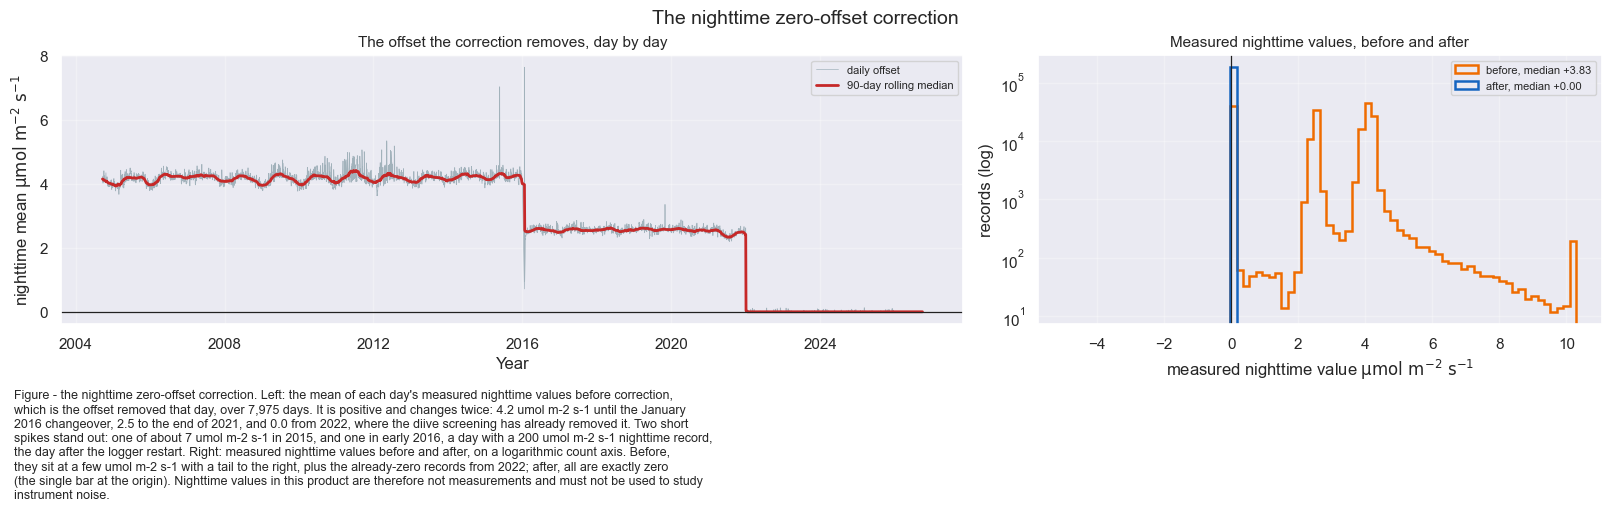

In [16]:
# What the correction removed. The offset is re-derived every day; this figure shows why it is
# not removed as a constant.
_offset_daily = PPFD_BEFORE_OFFSET.where(_night).resample('D').mean().dropna()

fig, axs = plt.subplots(ncols=2, figsize=(16, 5), dpi=100, layout='constrained',
                        width_ratios=[1.6, 1])
fig.suptitle('The nighttime zero-offset correction', fontsize=14)

axs[0].plot(_offset_daily.index, _offset_daily, color='#90A4AE', lw=0.5, alpha=0.8,
            label='daily offset')
axs[0].plot(_offset_daily.index, _offset_daily.rolling(90, center=True, min_periods=30).median(),
            color='#C62828', lw=2.0, label='90-day rolling median')
axs[0].axhline(0, color='#212121', lw=0.9)
axs[0].set_xlabel('Year')
axs[0].set_ylabel(r'nighttime mean $\mathrm{\mu mol\ m^{-2}\ s^{-1}}$')
axs[0].set_title('The offset the correction removes, day by day', fontsize=11)
axs[0].legend(fontsize=8)
axs[0].grid(alpha=0.3)

_nb = PPFD_BEFORE_OFFSET.where(_night).dropna()
_na = ppfd_2004_2026[TARGET].where(~PPFD_ORIGINAL_GAPS).where(_night).dropna()
_edges = np.linspace(min(-5, float(_nb.quantile(0.001))), max(5, float(_nb.quantile(0.999))), 81)
axs[1].hist(_nb.clip(_edges[0], _edges[-1]), bins=_edges, histtype='step', lw=1.8,
            color='#EF6C00', label=f'before, median {_nb.median():+.2f}')
axs[1].hist(_na.clip(_edges[0], _edges[-1]), bins=_edges, histtype='step', lw=1.8,
            color='#1565C0', label=f'after, median {_na.median():+.2f}')
axs[1].axvline(0, color='#212121', lw=0.9)
axs[1].set_yscale('log')
axs[1].set_xlabel(r'measured nighttime value $\mathrm{\mu mol\ m^{-2}\ s^{-1}}$')
axs[1].set_ylabel('records (log)')
axs[1].set_title('Measured nighttime values, before and after', fontsize=11)
axs[1].legend(fontsize=8)
axs[1].grid(alpha=0.3)

_eras = {'2004-2015': _offset_daily.loc[:'2015-12-31'].median(),
         '2016-2021': _offset_daily.loc['2016-02-01':'2021-12-31'].median(),
         '2022-2026': _offset_daily.loc['2022-01-01':].median()}
print("median daily nighttime offset, by acquisition and screening era "
      "(umol m-2 s-1):")
for _k, _v in _eras.items():
    print(f"  {_k}: {_v:.2f}")

figcap(fig, f"the nighttime zero-offset correction. Left: the mean of each day's measured "
            f"nighttime values before correction, which is the offset removed that day, over "
            f"{len(_offset_daily):,} days. It is positive and changes twice: "
            f"{_eras['2004-2015']:.1f} umol m-2 s-1 until the January 2016 changeover, "
            f"{_eras['2016-2021']:.1f} to the end of 2021, and {_eras['2022-2026']:.1f} from 2022, "
            f"where the diive screening has already removed it. Two short spikes stand out: one of "
            f"about 7 umol m-2 s-1 in 2015, and one in early 2016, a day with a 200 umol m-2 s-1 "
            f"nighttime record, the day after the logger restart. "
            f"Right: measured nighttime values before and after, on a logarithmic count axis. "
            f"Before, they sit at a few umol m-2 s-1 with a tail to the right, plus the "
            f"already-zero records from 2022; after, all are exactly zero (the single bar at the "
            f"origin). Nighttime values in this product are therefore not measurements and must "
            f"not be used to study instrument noise.")

***

## 🟦 Drivers

`PPFD_IN` and `SW_IN` measure nearly the same flux in different units, so the gap-filled `SW_IN`
of notebook `01` is the main driver. `SW_IN_POT` adds sun angle and season, which separate a clear
morning from a clear afternoon of equal `SW_IN`.

**MeteoSwiss Lägern** (`SW_IN_LAE_MS`) is added below as an independent measurement, because
`PPFD_IN` gaps tend to coincide with `SW_IN` gaps (same faults), where the tower driver is a model
output.

All three drivers span the record, so it is **not split into periods** (in `01` and `02` NABEL
ends in 2018).

### 📋 Table: tower SW_IN and potential radiation

In [17]:
swin_gf = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{SWIN_FILE}.parquet"))
print(f"Loaded {SWIN_FILE}: {list(swin_gf.columns)}")

drivers = pd.DataFrame(index=ppfd_2004_2026.index)
drivers[SWIN_COL] = swin_gf[SWIN_COL]  # keeps the name it has in the file
drivers['SW_IN_POT'] = dv.variables.potrad(
    timestamp_index=ppfd_2004_2026.index, lat=SITE_LAT, lon=SITE_LON,
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)

print(drivers.isnull().sum().rename('missing values'))
tabcap("the two drivers before the reference is added: gap-filled tower SW_IN from notebook 01 "
       "and potential radiation from the site coordinates. Both are complete by construction, so "
       "neither alone tells the model what the sky was doing")
drivers.describe()

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\01_METEO_SW_IN_GAPFILLED_2004-2026.09.parquet (0.043 seconds).

Loaded 01_METEO_SW_IN_GAPFILLED_2004-2026.09: ['SW_IN_T1_47_1_gfXG', 'FLAG_SW_IN_T1_47_1_ISFILLED']
SW_IN_T1_47_1_gfXG    0
SW_IN_POT             0
Name: missing values, dtype: int64
Table - the two drivers before the reference is added: gap-filled tower SW_IN from notebook 01 and
potential radiation from the site coordinates. Both are complete by construction, so neither alone
tells the model what the sky was doing



,SW_IN_T1_47_1_gfXG,SW_IN_POT
count,398832.000000,398832.000000
mean,147.611918,300.521731
std,241.952322,383.652942
min,0.000000,0.000000
25%,0.000000,0.000000
50%,4.298509,18.896021
75%,201.665094,571.615871
max,1118.658439,1214.125501


### 🌍 MeteoSwiss Lägern

Stored on `TIMESTAMP_END` and shifted back 15 minutes to `TIMESTAMP_MID`. The guard correlates it
with measured `PPFD_IN` in daytime and asserts that offset 0 wins, so a mis-shifted reference
cannot teach the model a wrong daily cycle.

#### 📋 Table: the three gap-filling drivers

In [18]:
ppfd_ref = pd.read_parquet(REFPATH)[[REFCOL]]
ppfd_ref.index = ppfd_ref.index - pd.Timedelta(minutes=15)  # TIMESTAMP_END -> TIMESTAMP_MID
ppfd_ref.index.name = ppfd_2004_2026.index.name

_meas = ppfd_2004_2026[TARGET]
_scores = {}
for _off in (-1, 0, 1):
    _j = pd.concat([_meas.rename('t'), ppfd_ref[REFCOL].shift(_off).rename('r')], axis=1).dropna()
    _j = _j[_j['r'] > 20]  # daytime only: at night both are ~0 and carry no timing information
    _scores[_off] = _j['t'].corr(_j['r'])
    print(f"  offset {_off:+d} x 30min: daytime corr {_scores[_off]:.4f}")
assert max(_scores, key=_scores.get) == 0, f"reference is mis-aligned: {_scores}"
print("OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.")

drivers[REFCOL] = ppfd_ref[REFCOL]
print(f"\n{REFCOL} available for {drivers[REFCOL].notna().mean() * 100:.2f}% of records")
tabcap("the three gap-filling drivers. MeteoSwiss is the only one with gaps of its own and the "
       "only measurement independent of this tower")
drivers.describe()

  offset -1 x 30min: daytime corr 0.9255
  offset +0 x 30min: daytime corr 0.9635
  offset +1 x 30min: daytime corr 0.9087
OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.

SW_IN_LAE_MS available for 99.60% of records
Table - the three gap-filling drivers. MeteoSwiss is the only one with gaps of its own and the only
measurement independent of this tower



,SW_IN_T1_47_1_gfXG,SW_IN_POT,SW_IN_LAE_MS
count,398832.000000,398832.000000,397230.000000
mean,147.611918,300.521731,143.265340
std,241.952322,383.652942,233.204243
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,2.000000
50%,4.298509,18.896021,5.666667
75%,201.665094,571.615871,193.000000
max,1118.658439,1214.125501,1155.333333


#### 📊 Plot: what the two drivers offer

How closely each driver tracks the target half-hour by half-hour sets the quality of a fill, which
`describe()` does not show.

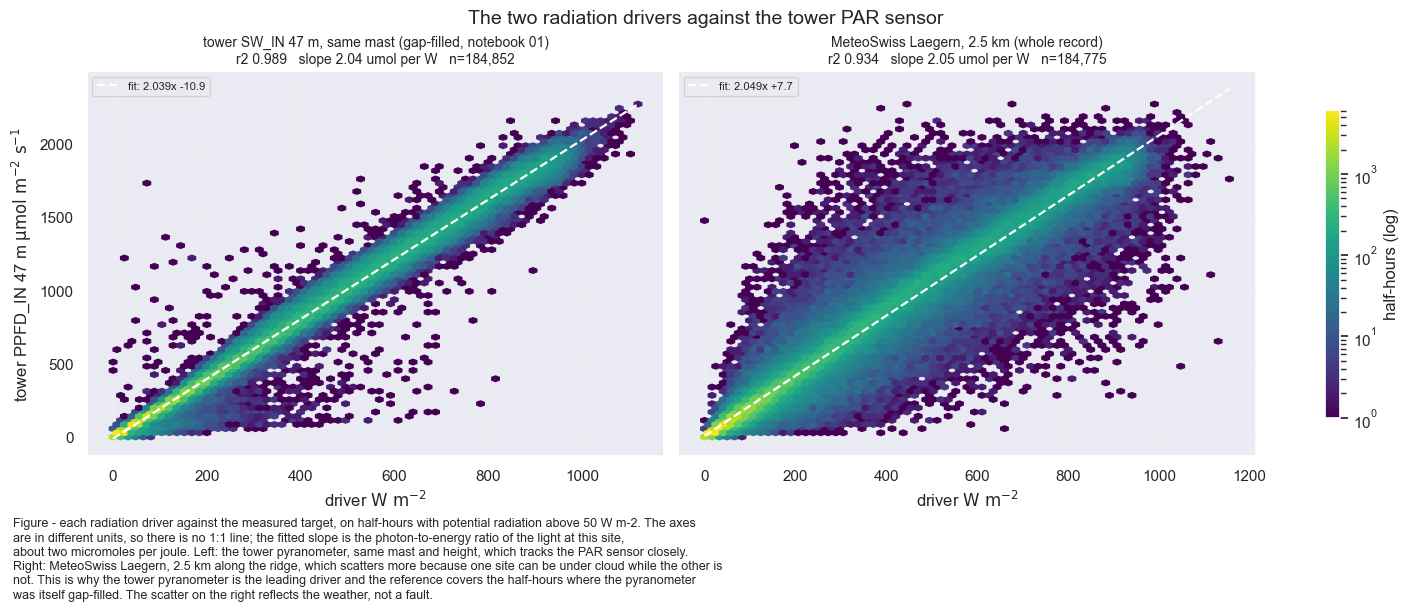

In [19]:
# Each driver against the target on lit half-hours: how tightly it tracks the target sets how
# good a fill from it can be.
_potrad_drv = drivers['SW_IN_POT']
_lit_drv = _potrad_drv > 50
_meas_drv = ppfd_2004_2026[TARGET].where(~PPFD_ORIGINAL_GAPS)

fig, axs = plt.subplots(ncols=2, figsize=(14, 6), dpi=100, layout='constrained', sharey=True)
fig.suptitle('The two radiation drivers against the tower PAR sensor', fontsize=14)

for _ax, _driver, _label in [
        (axs[0], SWIN_COL, 'tower SW_IN 47 m, same mast (gap-filled, notebook 01)'),
        (axs[1], REFCOL, 'MeteoSwiss Laegern, 2.5 km (whole record)')]:
    _j = pd.concat([_meas_drv.rename('t'), drivers[_driver].rename('d')], axis=1)[_lit_drv].dropna()
    _hb = _ax.hexbin(_j['d'], _j['t'], gridsize=70, mincnt=1, bins='log', cmap='viridis')
    _lim = [0, float(_j['d'].max())]
    _slope, _icpt = np.polyfit(_j['d'].to_numpy(), _j['t'].to_numpy(), 1)
    _ax.plot(_lim, [_slope * _x + _icpt for _x in _lim], color='w', lw=1.6, ls='--',
             label=f'fit: {_slope:.3f}x {_icpt:+.1f}')
    _r2 = _j['d'].corr(_j['t']) ** 2
    _ax.set_title(f"{_label}\nr2 {_r2:.3f}   slope {_slope:.2f} umol per W   n={len(_j):,}",
                  fontsize=10)
    _ax.set_xlabel(r'driver $\mathrm{W\ m^{-2}}$')
    _ax.legend(fontsize=8, loc='upper left')
    _ax.grid(alpha=0.2)
axs[0].set_ylabel(r'tower PPFD_IN 47 m $\mathrm{\mu mol\ m^{-2}\ s^{-1}}$')
fig.colorbar(_hb, ax=axs, label='half-hours (log)', shrink=0.8)

figcap(fig, "each radiation driver against the measured target, on half-hours with potential "
            "radiation above 50 W m-2. The axes are in different units, so there is no 1:1 line; "
            "the fitted slope is the photon-to-energy ratio of the light at this site, about two "
            "micromoles per joule. Left: the tower pyranometer, same mast and height, which tracks "
            "the PAR sensor closely. Right: MeteoSwiss Laegern, 2.5 km along the ridge, which "
            "scatters more because one site can be under cloud while the other is not. This is "
            "why the tower pyranometer is the leading driver and the reference covers the "
            "half-hours where the pyranometer was itself gap-filled. The scatter on the right "
            "reflects the weather, not a fault.")

***

## 🔎 Which sensor this is, and what the hardware changes did to it

The tower logger was replaced on 21 January 2016, and `TA_T1_47_1` steps by about 1.3 °C there
(notebook `02`). The fieldbook also records **a Kipp & Zonen PAR sensor installed on 8 January
2016**, so the question is whether the column is the same instrument across that month.

It is. The steps below show that:

1. the exported column is the Delta-T sunshine sensor, not the Kipp & Zonen PAR LITE;
2. the record begins after that sensor replaced a different probe at the same storage location;
3. the PAR LITE has its own column, which starts at the changeover;
4. there is no step at January 2016;
5. the 2011 and 2013 changes are not this sensor;
6. there is no step at the December 2021 screening splice;
7. the fieldbook records no replacement or calibration of this sensor;
8. **the sensor's response fell between the 2022 and 2024 seasons** and has not recovered; the fall
   has not continued since 2024. This is the only finding that is not a negative result, and a
   limitation of the product.

`RADIATION_SENSOR_CONTINUITY.ipynb` makes the full attribution, with the NABEL pyranometer at 49 m
as a fourth witness, and places the decline on this sensor. This section carries what bears on
this product and the assertions that keep it true.

### Helpers for this section

The logger programs and the fieldbook are read, not quoted, so a re-run re-derives the argument.
Both name people and this notebook is published, so every extracted string is redacted as in
notebooks `01`, `02` and `08`.

In [20]:
# --- Fieldbook and logger-program redaction ----------------------------------------------------
# The GIN export and the logger programs both name people and this notebook renders to a public
# page, so every extracted string passes through redact_people() where it is flattened. Same map
# and rules as notebooks 01, 02 and 08; the map lives beside the export, OUTSIDE this repository.
REDACT_MAP = Path(FIELDBOOK).with_name('redact_names.csv')
ALLOW_LIST = Path(FIELDBOOK).with_name('redact_allow.csv')


def unmapped_report_path(label: str) -> Path:
    """Where the unmapped-name candidates of one audit are written.

    Per label, because this notebook audits two sources: a single shared file would let the
    second audit overwrite the first one's findings.
    """
    _slug = re.sub(r'[^a-z0-9]+', '_', label.lower()).strip('_')
    return Path(FIELDBOOK).with_name(f'redact_unmapped_{_slug}.txt')


def load_redactions(path=None) -> dict:
    """Load the name -> pseudonym map.

    Raises if the map is missing. That is the point: carrying on with redaction quietly disabled
    prints real names into a published page and looks exactly like success.
    """
    path = REDACT_MAP if path is None else Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"the redaction map is missing: {path}. Without it the names these files record would "
            f"print unredacted. Restore the file rather than skipping this.")
    tab = pd.read_csv(path, encoding='utf-8')
    missing = {'name', 'pseudonym'}.difference(tab.columns)
    if missing:
        raise ValueError(f"{path}: missing column(s) {sorted(missing)}.")
    pairs = {str(n).strip(): str(p).strip()
             for n, p in zip(tab['name'], tab['pseudonym']) if str(n).strip()}
    if not pairs:
        raise ValueError(f"{path}: holds no usable name -> pseudonym pairs.")
    return pairs


REDACTIONS = load_redactions()
# Longest surface form first, so a bare surname cannot corrupt a double-barrelled one that starts
# with it. Lookarounds rather than \b, because some forms end in an initial.
_REDACT_RX = re.compile(r'(?<!\w)(' + '|'.join(re.escape(n) for n in
                                               sorted(REDACTIONS, key=len, reverse=True))
                        + r')(?!\w)')


def redact_people(s) -> str:
    """Replace every mapped name with its stable pseudonym."""
    return _REDACT_RX.sub(lambda m: REDACTIONS[m.group(1)], str(s))


def strip_html(text) -> str:
    """Flatten one GIN fieldbook entry to plain text, with the people it names redacted."""
    flat = html.unescape(re.sub(r'<[^>]+>', ' ', str(text)))
    return redact_people(re.sub(r'\s+', ' ', flat).strip())


_NAME_TOKEN = r"[A-ZÄÖÜ][\wÄÖÜäöüß'-]{1,20}"
_NAME_UNIT = _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r'){0,2}'
_NAME_SHAPES = (
    re.compile(r'\((' + _NAME_UNIT + r'(?:\s*[,+&]\s*' + _NAME_UNIT + r')*)\s*'
               r'(?:\d{1,2}\.\d{1,2}\.\d{4})?\)'),
    re.compile(r'(?:with|by|durch|von|gemaess)\s+(' + _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r')?)'),
)


def audit_unmapped_names(texts, label='fieldbook', write_report: bool = True) -> int:
    """Raise if any name-shaped token survived redaction.

    A newer export can name someone the map has never seen. Candidates are never printed - an
    exception message is stored in a notebook like any other output - so they go to a file beside
    the map and only the count is shown.
    """
    allow = set(pd.read_csv(ALLOW_LIST, encoding='utf-8')['term'].astype(str).str.strip())
    found = {}
    for _t in texts:
        for _rx in _NAME_SHAPES:
            for _m in _rx.finditer(str(_t)):
                for _tok in re.findall(_NAME_TOKEN, _m.group(1)):
                    if _tok.isupper() or any(ch.isdigit() for ch in _tok) or _tok in allow:
                        continue
                    found[_tok] = found.get(_tok, 0) + 1
    if found:
        _report = unmapped_report_path(label)
        if write_report:
            _report.write_text(
                '\n'.join(f'{n}\t{t}' for t, n in sorted(found.items(), key=lambda kv: -kv[1])),
                encoding='utf-8')
        raise ValueError(
            f"{label}: {len(found)} name-shaped token(s) survived redaction. They are deliberately "
            f"NOT shown here - see {_report}. Add the people to redact_names.csv and the "
            f"technical terms to redact_allow.csv, then re-run.")
    print(f"  {label}: no unmapped name-shaped tokens ({len(allow)} allowlisted terms)")
    return 0


def program_excerpt(path, pattern: str, before: int = 6, after: int = 4, expect: int = 1) -> str:
    """The lines of a logger program around `pattern`, redacted.

    Only the matched instruction is returned, never the file header: these programs are signed by
    their authors. Raises unless the pattern matches exactly `expect` times. Both directions
    matter: no match reads as 'the program does not measure this', and an over-broad pattern
    quietly prints the wrong instruction next to the argument it is supposed to support.
    """
    lines = Path(path).read_text(encoding='latin-1').splitlines()
    blocks = []
    for i, line in enumerate(lines):
        if re.search(pattern, line):
            lo, hi = max(0, i - before), min(len(lines), i + after + 1)
            blocks.append('\n'.join(lines[lo:hi]))
    if len(blocks) != expect:
        raise ValueError(f"{Path(path).name}: {pattern!r} matched {len(blocks)} time(s), expected "
                         f"{expect}. The program layout has changed, the wrong file is configured, "
                         f"or the pattern is not specific enough.")
    return redact_people('\n\n'.join(blocks))


_ARITHMETIC = re.compile(r'^[0-9.\s()*/+-]+$')


def program_constants(path) -> dict:
    """Every `Const <name> = <expression>` declared in a CR1000 program, evaluated.

    The CR1000 program writes the PPFD multipliers as arithmetic on the calibration certificate
    (`1/5.65*1000` for 5.65 uV per umol m-2 s-1) and names the result in the measurement
    instruction, so the declarations must be parsed to obtain a number.

    Only digits, spaces, brackets and the four arithmetic operators are evaluated, so a program
    cannot make this cell run code. Raises if no constant is declared, rather than returning an
    empty dict that would make a later lookup fail less informatively.
    """
    text = Path(path).read_text(encoding='latin-1')
    out = {}
    for _name, _expr in re.findall(r'^\s*Const\s+(\w+)\s*=\s*([^\'\r\n]+)', text, re.M):
        _expr = _expr.strip()
        if not _ARITHMETIC.match(_expr):
            continue
        try:
            out[_name] = float(eval(_expr, {'__builtins__': {}}, {}))
        except (SyntaxError, ZeroDivisionError, TypeError):
            continue
    if not out:
        raise ValueError(f"{Path(path).name}: no numeric `Const` declaration found. This program "
                         f"language does not declare constants, or the layout has changed.")
    return out


def calibration_constants(excerpt: str, consts: dict | None = None) -> dict:
    """The multiplier and offset of one measurement instruction, parsed from its own text.

    The CR10X lists both numbers as numbered parameters; the CR1000 passes them as the last two
    arguments of `VoltSe(...)` or `VoltDiff(...)`, possibly as the *name* of a declared constant,
    which `consts` resolves.

    Raises if either number is missing or a name cannot be resolved: an empty result would let the
    comparison below pass with nothing to disagree about.
    """
    if 'Mult' in excerpt:                                    # CR10X parameter listing
        _m = re.search(r'^\s*\d+:\s*([\d.]+)\s+Mult', excerpt, re.M)
        _o = re.search(r'^\s*\d+:\s*([\d.]+)\s+Offset', excerpt, re.M)
        tokens = [_m.group(1) if _m else None, _o.group(1) if _o else None]
    else:                                                    # CR1000 VoltSe/VoltDiff call
        _call = re.search(r'Volt(?:Se|Diff)\s*\(([^)]*)\)', excerpt)
        _args = [a.strip() for a in _call.group(1).split(',')] if _call else []
        tokens = _args[-2:] if len(_args) >= 2 else [None, None]

    values = []
    for _tok in tokens:
        if _tok is None:
            raise ValueError("could not parse a multiplier and an offset from the instruction - "
                             "the program language or the layout has changed")
        try:
            values.append(float(_tok))
        except ValueError:
            if not consts or _tok not in consts:
                raise ValueError(
                    f"the instruction gives its constant as the name {_tok!r}, which is not among "
                    f"the declarations passed in. Parse the program's `Const` block and pass it as "
                    f"`consts`, rather than reporting a constant this notebook cannot read.")
            values.append(consts[_tok])
    return {'multiplier': values[0], 'offset': values[1]}

In [21]:
# Negative controls: every failure path of the helpers is exercised before anything is read.
try:
    program_excerpt(PROGRAM_AFTER, r'ThisPatternIsNotInAnyLoggerProgram')
except ValueError as _exc:
    print(f"OK, program_excerpt raised on a pattern that does not occur: {_exc}")
else:
    raise AssertionError("(!) program_excerpt accepted a pattern that does not occur.")

# 'Ada Lovelace' is an invented name for this control. It writes no report, so the real one is
# not overwritten.
try:
    audit_unmapped_names(['12.05.2019 (Ada Lovelace) replaced the logger battery'],
                         'positive control', write_report=False)
except ValueError:
    print("OK, the unknown-name net fired on a name that is not in the map")
else:
    raise AssertionError("(!) the unknown-name net did not fire on an unmapped name.")

# The constant parser must refuse an instruction it cannot read at all ...
try:
    calibration_constants("18:  Volt (Diff) (P2) ;Messung von Kin\n 1: 1        Reps")
except ValueError as _exc:
    print(f"OK, calibration_constants raised on an instruction with no constants: {_exc}")
else:
    raise AssertionError("(!) calibration_constants accepted an instruction carrying no constants.")

# ... and one whose constant is a NAME it has no value for. This path is new relative to 01: the
# CR1000 names its PPFD multipliers, and a literal-only parser would miss or misread them.
try:
    calibration_constants("VoltDiff(PPFD_IN_T1_47_2,1,mV25,1,True,0,_50Hz,PPFD_IN_T1_47_2_mult,0)",
                          consts={})
except ValueError as _exc:
    print(f"OK, calibration_constants raised on an unresolved named constant: {_exc}")
else:
    raise AssertionError("(!) calibration_constants accepted a constant it could not resolve.")

# The declaration parser must refuse a program without declarations instead of returning an
# empty mapping.
try:
    program_constants(PROGRAMS_BF2[0])
except ValueError as _exc:
    print(f"OK, program_constants raised on a program that declares no constants: {_exc}")
else:
    raise AssertionError("(!) program_constants accepted a program with no `Const` declarations.")

OK, program_excerpt raised on a pattern that does not occur: CH-LAE_iDL_T1_47_1.CR1: 'ThisPatternIsNotInAnyLoggerProgram' matched 0 time(s), expected 1. The program layout has changed, the wrong file is configured, or the pattern is not specific enough.
OK, the unknown-name net fired on a name that is not in the map
OK, calibration_constants raised on an instruction with no constants: could not parse a multiplier and an offset from the instruction - the program language or the layout has changed
OK, calibration_constants raised on an unresolved named constant: the instruction gives its constant as the name 'PPFD_IN_T1_47_2_mult', which is not among the declarations passed in. Parse the program's `Const` block and pass it as `consts`, rather than reporting a constant this notebook cannot read.
OK, program_constants raised on a program that declares no constants: LAEGEREN.20040810.CSI: no numeric `Const` declaration found. This program language does not declare constants, or the layout h

### 1️⃣ The exported column is the Delta-T sensor, not the Kipp & Zonen PAR LITE

`PPFD_IN_T1_47_1` and `PPFD_IN_T1_47_2` are both incoming PAR at 47 m under one fieldbook operation
tag. The CR1000 program separates them: it names each sensor in a comment and applies a different
conversion to each.

#### 📋 Table: the two PAR measurements at 47 m

In [22]:
# Which instrument the exported column is, read from the CR1000 program. It measures both PAR
# sensors at 47 m under the field names the database uses.
CR1000_CONSTS = program_constants(PROGRAM_AFTER)
print(f"{Path(PROGRAM_AFTER).name} declares {len(CR1000_CONSTS)} constants; the PPFD ones are")
for _k, _v in CR1000_CONSTS.items():
    if 'PPFD' in _k:
        print(f"    {_k:<28s} = {_v:.4f}")

SENSORS_2016 = {}
print("\n" + "=" * 78)
print(f"{TARGET}: the exported column")
print("=" * 78)
_ex_bf3 = program_excerpt(PROGRAM_AFTER, rf'VoltSe \({TARGET}', before=2, after=1)
print(_ex_bf3)
SENSORS_2016[TARGET] = calibration_constants(_ex_bf3, consts=CR1000_CONSTS)

print("\n" + "=" * 78)
print(f"{SECOND_SENSOR}: the sensor the fieldbook records being installed in January 2016")
print("=" * 78)
_ex_parlite = program_excerpt(PROGRAM_AFTER, rf'VoltDiff\({SECOND_SENSOR}', before=1, after=0)
print(_ex_parlite)
SENSORS_2016[SECOND_SENSOR] = calibration_constants(_ex_parlite, consts=CR1000_CONSTS)

audit_unmapped_names([_ex_bf3, _ex_parlite], 'CR1000 program')

tabcap("the two incoming-PAR measurements of the CR1000 program at 47 m and the conversion each "
       "applies. They are different instruments on different channels; only the first is exported")
_s16 = pd.DataFrame(SENSORS_2016).T
_s16.index.name = 'field name'
_s16['instrument (from the program comments)'] = ['Delta-T BF2/BF3 sunshine sensor',
                                                  'Kipp & Zonen PAR LITE']
display(_s16)

# The identification: the BF2/BF3 outputs umol m-2 s-1 directly (multiplier exactly 1); the PAR
# LITE is a raw-microvolt sensor whose multiplier is the reciprocal of its sensitivity.
assert SENSORS_2016[TARGET] == {'multiplier': 1.0, 'offset': 0.0}, (
    f"{TARGET} is no longer measured at multiplier 1 and offset 0 - the exported column may not be "
    f"the Delta-T sensor any more and the whole of this section must be re-derived")
assert abs(SENSORS_2016[SECOND_SENSOR]['multiplier'] - 1000 / 5.65) < 0.01, (
    f"{SECOND_SENSOR} is no longer measured at the reciprocal of the PAR LITE sensitivity the "
    f"fieldbook records (5.65 uV per umol m-2 s-1)")
print(f"\n{TARGET} is the Delta-T sunshine sensor: multiplier 1, offset 0, single-ended.")
print(f"{SECOND_SENSOR} is the Kipp & Zonen PAR LITE: multiplier "
      f"{SENSORS_2016[SECOND_SENSOR]['multiplier']:.2f}, the reciprocal of its "
      f"{1000 / SENSORS_2016[SECOND_SENSOR]['multiplier']:.2f} uV per umol m-2 s-1 sensitivity.")

CH-LAE_iDL_T1_47_1.CR1 declares 5 constants; the PPFD ones are
    PPFD_IN_T1_47_2_mult         = 176.9912
    PPFD_OUT_T1_47_1_mult        = 178.8909
    PPFD_OUT_T1_47_2_mult        = 190.1141

PPFD_IN_T1_47_1: the exported column
    If WS_CUP_SCALAR_T1_47_1<0.258 Then WS_CUP_SCALAR_T1_47_1=0
    'BF3 output
    VoltSe (PPFD_IN_T1_47_1,1,mV2500,10,1,0,_50Hz,1.0,0)
    VoltSe (PPFD_DIF_T1_47_1,1,mV2500,11,1,0,_50Hz,1.0,0)

PPFD_IN_T1_47_2: the sensor the fieldbook records being installed in January 2016
        'Kipp&Zonen PAR LITE
        VoltDiff(PPFD_IN_T1_47_2,1,mV25,1,True,0,_50Hz,PPFD_IN_T1_47_2_mult,0)
  CR1000 program: no unmapped name-shaped tokens (58 allowlisted terms)
Table - the two incoming-PAR measurements of the CR1000 program at 47 m and the conversion each
applies. They are different instruments on different channels; only the first is exported



,multiplier,offset,instrument (from the program comments)
field name,,,
PPFD_IN_T1_47_1,1.00000,0.0,Delta-T BF2/BF3 sunshine sensor
PPFD_IN_T1_47_2,176.99115,0.0,Kipp & Zonen PAR LITE



PPFD_IN_T1_47_1 is the Delta-T sunshine sensor: multiplier 1, offset 0, single-ended.
PPFD_IN_T1_47_2 is the Kipp & Zonen PAR LITE: multiplier 176.99, the reciprocal of its 5.65 uV per umol m-2 s-1 sensitivity.


The Delta-T sunshine sensor outputs µmol m⁻² s⁻¹ directly, so its multiplier is exactly `1`. The
PAR LITE outputs microvolts, so its multiplier is the reciprocal of its sensitivity, the
`5.65 µV per µmol m⁻² s⁻¹` the fieldbook records for the sensor installed in January 2016.

::: {.callout-note title="Why the multiplier being 1 matters, and what it hides"}
The January 2016 logger replacement cannot have rescaled this series: there was no scale factor
to get wrong. The calibration lives **inside the sensor**, where no logger program records it.
This is what makes step 8️⃣ possible.
:::

### 2️⃣ The record begins after that sensor was installed

The CR10X program of May 2004 writes a **Skye PAR-1** probe to this storage location at multiplier
`3`; the program of 10 August 2004 moves that probe to reflected PAR and puts the Delta-T sensor in
its place. A record starting earlier would hold two instruments in one column.

#### 📋 Table: PAR conversion per logger program

In [23]:
# This section compares MEASURED records. After the offset correction notna() no longer means
# measured (every nighttime gap is zero, and the record would appear to start on 1 January 2004),
# so the mask captured before it is used.
PPFD_MEASURED = ppfd_2004_2026[TARGET].where(~PPFD_ORIGINAL_GAPS)
print(f"measured records: {int(PPFD_MEASURED.notna().sum()):,}; "
      f"nighttime gaps the correction filled with zero: "
      f"{int((PPFD_ORIGINAL_GAPS & ppfd_2004_2026[TARGET].notna()).sum()):,}")

# All five CR10X programs with the Delta-T sensor are parsed. The May 2004 program writes a
# DIFFERENT sensor to the same storage location, which is why this step exists.
CR10X_CONSTANTS, _cr10x_excerpts = {}, []
for _p in PROGRAMS_BF2:
    _ex = program_excerpt(_p, r'BF2 total PAR', before=0, after=10)
    _cr10x_excerpts.append(_ex)
    CR10X_CONSTANTS[Path(_p).name] = calibration_constants(_ex)
print(f"--- {Path(PROGRAMS_BF2[0]).name}, the first program carrying the Delta-T sensor")
print(_cr10x_excerpts[0])

_ex_skye = program_excerpt(PROGRAM_BEFORE_BF2, r'the PAR-1 probe has an output', before=2, after=12)
print(f"\n--- {Path(PROGRAM_BEFORE_BF2).name}, the program before it")
print(_ex_skye)
SKYE = calibration_constants(_ex_skye)
audit_unmapped_names(_cr10x_excerpts + [_ex_skye], 'CR10X programs')

tabcap("the conversion each surviving program applies to the incoming-PAR storage location, "
       "oldest first. The May 2004 program measures a different probe there at a different "
       "multiplier; from August 2004 every program applies the same conversion as the CR1000 "
       "after 2016")
_prog = pd.DataFrame({**{Path(PROGRAM_BEFORE_BF2).name: SKYE}, **CR10X_CONSTANTS,
                      **{Path(PROGRAM_AFTER).name: SENSORS_2016[TARGET]}}).T
_prog.index.name = 'logger program'
_prog['sensor'] = (['Skye PAR-1 (reflected PAR from Aug 2004)']
                   + ['Delta-T BF2'] * len(CR10X_CONSTANTS) + ['Delta-T BF3'])
display(_prog)

# One conversion in every program measuring this sensor. A multiplier changed at 2016 would make
# the series step there by construction, and the ratios below would measure that.
_mults = {v['multiplier'] for v in CR10X_CONSTANTS.values()} | {SENSORS_2016[TARGET]['multiplier']}
_offsets = {v['offset'] for v in CR10X_CONSTANTS.values()} | {SENSORS_2016[TARGET]['offset']}
print(f"\ndistinct multipliers over the {len(CR10X_CONSTANTS) + 1} programs measuring the "
      f"Delta-T sensor: {sorted(_mults)}")
print(f"distinct offsets: {sorted(_offsets)}")
assert _mults == {1.0} and _offsets == {0.0}, (
    "the programs do not all apply the same conversion to the Delta-T sensor - the argument that "
    "the 2016 changeover cannot have rescaled this series no longer holds")

# The record must not reach back into the Skye PAR-1 era (May 2004 program, multiplier 3), or the
# column would mix two instruments, as the SWC names do.
RECORD_START = PPFD_MEASURED.dropna().index[0]
BF2_PROGRAM = pd.Timestamp(re.search(r'\.(\d{8})\.', Path(PROGRAMS_BF2[0]).name).group(1))
print(f"\nfirst program carrying the Delta-T sensor: {BF2_PROGRAM:%d %b %Y}")
print(f"first measured {TARGET} record:            {RECORD_START:%d %b %Y %H:%M}")
print(f"difference: {(RECORD_START.normalize() - BF2_PROGRAM).days} days")
print(f"multiplier of the probe that preceded it:  {SKYE['multiplier']}")
assert RECORD_START >= BF2_PROGRAM, (
    "the record begins before the Delta-T sensor was programmed into this storage location, so "
    "its earliest values belong to the Skye probe and the column spans two instruments")
assert (RECORD_START.normalize() - BF2_PROGRAM).days < 120, (
    "the record no longer begins soon after the sensor was programmed - the identification of the "
    "instrument at the start of the record needs re-checking")

measured records: 382,228; nighttime gaps the correction filled with zero: 7,543
--- LAEGEREN.20040810.CSI, the first program carrying the Delta-T sensor
; BF2 total PAR
;--------------------

5:  Volt (SE) (P1)
 1: 1        Reps
 2: 35       2500 mV 50 Hz Rejection Range
 3: 1        SE Channel
 4: 20       Loc [ PPFD      ]
 5: 1.0      Mult
 6: 0.0      Offset


--- LAEGEREN.20040526.CSI, the program before it
; PAR sensor
;-----------
; the PAR-1 probe has an output of 0-1 V for 0-3000 micro-mol/m2/s
; it was attached to 3H and 3L where the CM3 up and CM3 down from
; the Kipp&Zonen CNR-1 were connected in earlier times.


9:  Volt (Diff) (P2)
 1: 1        Reps
 2: 35       2500 mV 50 Hz Rejection Range
 3: 3        DIFF Channel
 4: 20       Loc [ PPFD      ]
 5: 3.0      Mult
 6: 0.0      Offset

  CR10X programs: no unmapped name-shaped tokens (58 allowlisted terms)
Table - the conversion each surviving program applies to the incoming-PAR storage location, oldest
first. The May 20

,multiplier,offset,sensor
logger program,,,
LAEGEREN.20040526.CSI,3.0,0.0,Skye PAR-1 (reflected PAR from Aug 2004)
LAEGEREN.20040810.CSI,1.0,0.0,Delta-T BF2
LAEGEREN.20041228.CSI,1.0,0.0,Delta-T BF2
LAEGEREN.20050818.CSI,1.0,0.0,Delta-T BF2
LAEGEREN.20050914.CSI,1.0,0.0,Delta-T BF2
LAEGEREN.20060524.csi,1.0,0.0,Delta-T BF2
CH-LAE_iDL_T1_47_1.CR1,1.0,0.0,Delta-T BF3



distinct multipliers over the 6 programs measuring the Delta-T sensor: [1.0]
distinct offsets: [0.0]

first program carrying the Delta-T sensor: 10 Aug 2004
first measured PPFD_IN_T1_47_1 record:            20 Sep 2004 10:45
difference: 41 days
multiplier of the probe that preceded it:  3.0


### 3️⃣ The sensor installed in January 2016 has its own column

The fieldbook entry of 8 January 2016 records the Kipp & Zonen installation but not which database
column it became, because GIN files both 47 m PAR sensors under one operation tag. The database
shows it.

#### 📋 Table: both PAR series around January 2016

In [24]:
%%time

# The second PAR sensor, neither driver nor output: the only way to separate the January 2016
# installation from the exported sensor. It exists under `meteoscreening_mst` only.
parlite, _, _ = dbc.download(
    bucket=BUCKET, measurements=MEASUREMENTS, fields=[SECOND_SENSOR],
    start='2004-01-01 00:00:01', stop='2026-10-01 00:00:01',
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version='meteoscreening_mst')
parlite = TimestampSanitizer(data=parlite, output_middle_timestamp=True,
                             nominal_freq=REQUIRED_TIME_RESOLUTION).get()

PARLITE_START = parlite[SECOND_SENSOR].dropna().index[0]
PARLITE_END = parlite[SECOND_SENSOR].dropna().index[-1]

# The changeover is dated by the outage in the data, not by the fieldbook, so both PAR series are
# dated against the same event.
_outage = PPFD_MEASURED.loc['2015-12-01':'2016-03-01']
OUTAGE_START = _outage.loc[:'2016-01-15'].dropna().index[-1]
RESUMED = _outage.loc['2016-01-15':].dropna().index[0]

tabcap("the two incoming-PAR series at 47 m around the January 2016 changeover. The exported "
       "column measures for eleven years before it; the Kipp & Zonen sensor installed that month "
       "has its own column, which starts at the changeover")
_span = pd.DataFrame({
    'first record': [RECORD_START, PARLITE_START],
    'last record': [PPFD_MEASURED.dropna().index[-1], PARLITE_END],
    'measured records': [int(PPFD_MEASURED.notna().sum()),
                         int(parlite[SECOND_SENSOR].notna().sum())],
    'records before the changeover': [
        int(PPFD_MEASURED.loc[:OUTAGE_START].notna().sum()),
        int(parlite.loc[:OUTAGE_START, SECOND_SENSOR].notna().sum())],
    'instrument': ['Delta-T BF2/BF3', 'Kipp & Zonen PAR LITE'],
}, index=[TARGET, SECOND_SENSOR])
display(_span)

print(f"\nthe tower stops recording after {OUTAGE_START:%d %b %Y %H:%M} and resumes at "
      f"{RESUMED:%d %b %Y %H:%M} ({(RESUMED - OUTAGE_START).days} days)")
print(f"{SECOND_SENSOR} first appears at    {PARLITE_START:%d %b %Y %H:%M}")

# Both columns resume together after the three-week outage, so continuity cannot separate them.
# Only one of them existed before, as the logger programs above explain.
assert parlite.loc[:OUTAGE_START, SECOND_SENSOR].notna().sum() == 0, (
    f"{SECOND_SENSOR} now carries measurements from before the changeover, so it is not the sensor "
    f"installed then and the identification in this step has to be re-made")
assert abs((PARLITE_START - RESUMED).total_seconds()) < 24 * 3600, (
    f"{SECOND_SENSOR} no longer begins when the tower record resumes, so it can no longer be tied "
    f"to the January 2016 installation")
assert PPFD_MEASURED.loc[:OUTAGE_START].notna().sum() > 100_000, (
    f"{TARGET} no longer has a substantial record before the changeover, which is the whole of "
    f"what distinguishes it from the sensor installed then")
print(f"\nThe January 2016 installation entered the database as {SECOND_SENSOR}, a column that "
      f"begins at the changeover. {TARGET} has "
      f"{int(PPFD_MEASURED.loc[:OUTAGE_START].notna().sum()):,} measured records before it.")

> DOWNLOADING from bucket ch-lae_processed: variables ['PPFD_IN_T1_47_2'] from measurements 
['PPFD'], data version ['meteoscreening_mst'], between 2004-01-01 00:00:01 and 2026-10-01 00:00:01 
(timezone offset to UTC 1)

> Downloaded data for 1 variables:

> <-- PPFD_IN_T1_47_2: 103,461 records from 2016-01-21 14:30:00 to 2022-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

Table - the two incoming-PAR series at 47 m around the January 2016 changeover. The exported column
measures for eleven years before it; the Kipp & Zonen sensor installed that month has its own
column, which starts at the changeover



,first record,last record,measured records,records before the changeover,instrument
PPFD_IN_T1_47_1,2004-09-20 10:45:00,2026-09-30 23:45:00,382228,195617,Delta-T BF2/BF3
PPFD_IN_T1_47_2,2016-01-21 14:15:00,2021-12-31 23:45:00,103461,0,Kipp & Zonen PAR LITE



the tower stops recording after 31 Dec 2015 23:45 and resumes at 21 Jan 2016 14:15 (20 days)
PPFD_IN_T1_47_2 first appears at    21 Jan 2016 14:15

The January 2016 installation entered the database as PPFD_IN_T1_47_2, a column that begins at the changeover. PPFD_IN_T1_47_1 has 195,617 measured records before it.
CPU times: total: 2.19 s
Wall time: 3.34 s


### 4️⃣ Reading the three series against each other

This sensor, the tower pyranometer and MeteoSwiss Lägern span the record. Of their three pairwise
ratios, a response change at one series moves the two it appears in and not the third (as in
notebook `02` and `RADIATION_SENSOR_CONTINUITY.ipynb`). The tower pyranometer is on the same
logger, so a change in this tower's acquisition system could leave its ratio with `PPFD_IN` flat;
nothing at the tower can move MeteoSwiss.

Only April-September enters. 2026 covers that season in full and enters like any other year.

In [25]:
# Radiation errors are multiplicative, so every comparison is a RATIO and every change a percentage.
# Three controls are built into the helper, because each could manufacture a change:
#   season: medians per calendar month, averaged over months, April-September only (snow, rime and
#     low-sun horizon differences read as response changes);
#   illumination: POTENTIAL radiation above WELL_LIT, which cannot drift, and both members above
#     MIN_IRRADIANCE (selecting on a measured series biases the ratio towards it);
#   sunniness: a ratio of two sensors is immune; a clear-sky index is not, and is not used here.
WELL_LIT = 300.0        # W m-2 of POTENTIAL radiation
MIN_IRRADIANCE = 50.0   # measured; W m-2 for the two shortwave series, umol m-2 s-1 for PPFD
SUMMER_MONTHS = [4, 5, 6, 7, 8, 9]
# The record covers April-September of its last year in full, so the partial year 2026 enters
# these yearly ratios like any other year. If PERIOD_END moves earlier, cap them at LAST_FULL_YEAR.
_season_end = (pd.Timestamp(pd.Timestamp(PERIOD_END).year, max(SUMMER_MONTHS), 1)
               + pd.offsets.MonthEnd(1) + pd.Timedelta(hours=23, minutes=45))
assert pd.Timestamp(PERIOD_END) >= _season_end, (
    f"the record ends at {PERIOD_END}, inside the April-September window of its last year, so that "
    f"year would enter the ratios with part of a season")
BASELINE_YEARS = (2006, 2010)

PPFD_47 = 'PPFD_IN 47 m'
SW_47 = 'SW_IN 47 m'
MS_SW = 'MeteoSwiss'
PARLITE_47 = 'PAR LITE 47 m'

# Measured records only on both sides: a filled SW_IN value is partly a function of the MeteoSwiss
# series it would be compared against, so the fill flag keeps it out. The PAR LITE (2016-2021) is
# carried alongside but is not one of the three ratios, because a column of mostly empty years
# invites reading a change off two rows.
rad = pd.DataFrame(index=ppfd_2004_2026.index)
rad[PPFD_47] = PPFD_MEASURED                    # never the nighttime zeros the correction wrote
rad[SW_47] = swin_gf[SWIN_COL].where(swin_gf[SWIN_FLAG] == 0)
rad[MS_SW] = drivers[REFCOL]
rad[PARLITE_47] = parlite[SECOND_SENSOR]

POTRAD = dv.variables.potrad(timestamp_index=rad.index, lat=SITE_LAT, lon=SITE_LON,
                             utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
USABLE = (POTRAD > WELL_LIT) & rad.index.month.isin(SUMMER_MONTHS)
print(f"usable half-hours (Apr-Sep, potential radiation > {WELL_LIT:.0f} W m-2): "
      f"{int(USABLE.sum()):,} of {len(rad):,}")


def ratio_by_year(num: str, den: str, min_records: int = 100) -> pd.Series:
    """Month-matched yearly median of `num`/`den` over usable half-hours.

    Monthly medians first, then the mean over calendar months, so a year short of one month is not
    compared against one that is not. Raises rather than returning a thin result: a ratio built
    from a handful of half-hours reads exactly like one built from a thousand.
    """
    _j = rad.loc[USABLE, [num, den]].dropna()
    _j = _j[(_j[num] > MIN_IRRADIANCE) & (_j[den] > MIN_IRRADIANCE)]
    if len(_j) < min_records * 12:
        raise ValueError(f"{num} / {den}: only {len(_j)} usable half-hours, too few to build "
                         f"monthly medians from")
    _r = _j[num] / _j[den]
    _m = _r.groupby([_r.index.year, _r.index.month]).median()
    _m.index.names = ['year', 'month']
    _n = _r.groupby([_r.index.year, _r.index.month]).count()
    _m = _m[_n >= min_records]
    if _m.empty:
        raise ValueError(f"{num} / {den}: no calendar month reaches {min_records} records")
    return _m.groupby(level=0).mean()


def step_at(series: pd.Series, year: int, span: int = 3) -> float:
    """Percentage change of a yearly ratio across `year`, over `span` years either side.

    The candidate year itself is excluded from both sides: a change inside a year belongs to
    neither era, and including it would halve the step it is meant to measure. Returns nan rather
    than a number when either side is thin, so a year at the edge of the record cannot win a scan
    by having almost no data behind it.
    """
    _pre = series.reindex(range(year - span, year)).dropna()
    _post = series.reindex(range(year + 1, year + 1 + span)).dropna()
    if len(_pre) < 2 or len(_post) < 2:
        return float('nan')
    return 100 * (_post.mean() / _pre.mean() - 1)


RATIOS = {f'{PPFD_47} / {SW_47}': ratio_by_year(PPFD_47, SW_47),
          f'{PPFD_47} / {MS_SW}': ratio_by_year(PPFD_47, MS_SW),
          f'{SW_47} / {MS_SW}': ratio_by_year(SW_47, MS_SW)}
PPFD_PAIRS = [_l for _l in RATIOS if _l.startswith(PPFD_47)]
ratio_table = pd.DataFrame(RATIOS)
ratio_table.index.name = 'YEAR'
relative = 100 * (ratio_table / ratio_table.loc[BASELINE_YEARS[0]:BASELINE_YEARS[1]].mean() - 1)

scan = pd.DataFrame({_l: {_y: step_at(_s, _y) for _y in _s.index}
                     for _l, _s in RATIOS.items()}).sort_index()
scan.index.name = 'YEAR'
assert len(PPFD_PAIRS) == 2, "the pair list has changed - re-check which pairs the assertions cover"

usable half-hours (Apr-Sep, potential radiation > 300 W m-2): 98,221 of 398,832


In [26]:
# Negative controls. ratio_by_year must raise both when the data are too few overall and when no
# single month is populated; step_at must return nan where one side of the comparison is missing.
for _thresh, _which in [(1_000_000, 'too few half-hours in total'),
                        (5_000, 'enough in total, but no single calendar month')]:
    try:
        ratio_by_year(PPFD_47, SW_47, min_records=_thresh)
    except ValueError as _exc:
        print(f"OK, ratio_by_year raised on '{_which}': {_exc}")
    else:
        raise AssertionError(f"(!) ratio_by_year accepted a threshold no data can meet ({_which}).")

_probe = ratio_by_year(PPFD_47, MS_SW)
assert np.isnan(step_at(_probe, 1990)), "(!) step_at returned a number for a year off the record"
assert np.isnan(step_at(_probe, int(_probe.index.max()))), \
    "(!) step_at returned a number for the last year of the record, which has no years after it"
print("OK, step_at returns nan where one side of the comparison does not exist")

OK, ratio_by_year raised on 'too few half-hours in total': PPFD_IN 47 m / SW_IN 47 m: only 84291 usable half-hours, too few to build monthly medians from
OK, ratio_by_year raised on 'enough in total, but no single calendar month': PPFD_IN 47 m / SW_IN 47 m: no calendar month reaches 5000 records
OK, step_at returns nan where one side of the comparison does not exist


### 5️⃣ No step at the January 2016 acquisition change

The change across 2016 is judged against the same statistic at every other year, not against zero.

#### 📋 Table: pairwise ratios by year

In [27]:
BREAK_YEAR = 2016

tabcap(f"each pairwise ratio by year, as a percentage of its own {BASELINE_YEARS[0]}-"
       f"{BASELINE_YEARS[1]} mean (April-September only, so {int(relative.index.max())} is "
       f"complete). A response change at one sensor moves every ratio it appears in and no other; "
       f"a row says nothing about how sunny a year was")
display(relative.round(2))

Table - each pairwise ratio by year, as a percentage of its own 2006-2010 mean (April-September
only, so 2026 is complete). A response change at one sensor moves every ratio it appears in and no
other; a row says nothing about how sunny a year was



,PPFD_IN 47 m / SW_IN 47 m,PPFD_IN 47 m / MeteoSwiss,SW_IN 47 m / MeteoSwiss
YEAR,,,
2004,NaN,-2.23,NaN
2005,-2.20,-1.01,1.57
2006,0.42,-0.30,-0.35
2007,0.45,0.62,-0.43
2008,-0.07,-0.40,-0.69
2009,-0.15,-0.30,0.15
2010,-0.65,0.38,1.31
2011,1.29,-4.00,-5.50
2012,0.20,-4.08,-4.41


#### 📋 Table: change across 2016

In [28]:
tabcap(f"the change across {BREAK_YEAR} in each ratio, against the same measurement in an "
       f"ordinary year and at its largest elsewhere in the record")
_rows = []
for _label, _s in RATIOS.items():
    _elsewhere = pd.Series({_y: step_at(_s, _y) for _y in _s.index if _y != BREAK_YEAR}).dropna()
    _rows.append({'pair': _label,
                  f'change across {BREAK_YEAR} (%)': step_at(_s, BREAK_YEAR),
                  'median |change| elsewhere (%)': _elsewhere.abs().median(),
                  'largest |change| elsewhere (%)': _elsewhere.abs().max(),
                  'year of that largest change': int(_elsewhere.abs().idxmax())})
break_table = pd.DataFrame(_rows).set_index('pair')
display(break_table.round(2))

# The 2 % event threshold of notebook 01 and RADIATION_SENSOR_CONTINUITY.ipynb, asserted to stay
# above the ordinary-year variability of every pair, below which it would fire on nothing.
EVENT_THRESHOLD = 2.0
assert EVENT_THRESHOLD > break_table['median |change| elsewhere (%)'].max(), (
    "the threshold has fallen below the median change these measurements find in an ordinary "
    "year, which would make it fire on nothing having happened")

# Asserted on the two pairs containing the tower PAR sensor. The third pair is the two references,
# which a change to this tower's logger cannot move.
for _label in PPFD_PAIRS:
    _row = break_table.loc[_label]
    _change = _row[f'change across {BREAK_YEAR} (%)']
    print(f"  {_label}: {_change:+.2f} % across {BREAK_YEAR}, against "
          f"{_row['median |change| elsewhere (%)']:.2f} % in a typical year and "
          f"{_row['largest |change| elsewhere (%)']:.2f} % at its worst "
          f"({int(_row['year of that largest change'])})")
    assert abs(_change) < EVENT_THRESHOLD, (
        f"{_label} changes by {_change:.2f} % across {BREAK_YEAR}, past the {EVENT_THRESHOLD} % an "
        f"event is counted at - PPFD_IN may have moved at the acquisition change after all, and "
        f"this section must be re-derived")
    assert abs(_change) < _row['largest |change| elsewhere (%)'], (
        f"{_label}: the change across {BREAK_YEAR} is now the largest in the record, which is the "
        f"opposite of what this section concludes")

# The pair against MeteoSwiss carries the argument: a rescaling of this tower's acquisition system
# could leave the two tower sensors' ratio flat, but not their ratio against MeteoSwiss.
print(f"\nBoth pairs containing the tower PAR sensor change by less than {EVENT_THRESHOLD} % "
      f"across {BREAK_YEAR}, and by less than they change at their worst elsewhere. The pair "
      f"against MeteoSwiss carries the argument: a change confined to this tower's acquisition "
      f"system could leave the two tower sensors' ratio unmoved, but not their ratio against a "
      f"station 2.5 km away.")

Table - the change across 2016 in each ratio, against the same measurement in an ordinary year and
at its largest elsewhere in the record



,change across 2016 (%),median |change| elsewhere (%),largest |change| elsewhere (%),year of that largest change
pair,,,,
PPFD_IN 47 m / SW_IN 47 m,0.42,0.68,3.54,2023
PPFD_IN 47 m / MeteoSwiss,0.52,1.67,4.51,2011
SW_IN 47 m / MeteoSwiss,-0.27,0.63,3.63,2010


  PPFD_IN 47 m / SW_IN 47 m: +0.42 % across 2016, against 0.68 % in a typical year and 3.54 % at its worst (2023)
  PPFD_IN 47 m / MeteoSwiss: +0.52 % across 2016, against 1.67 % in a typical year and 4.51 % at its worst (2011)

Both pairs containing the tower PAR sensor change by less than 2.0 % across 2016, and by less than they change at their worst elsewhere. The pair against MeteoSwiss carries the argument: a change confined to this tower's acquisition system could leave the two tower sensors' ratio unmoved, but not their ratio against a station 2.5 km away.


The series does not step. Only the sensor's **dark signal** changed, from about 4.2 to about
2.5 µmol m⁻² s⁻¹ (offset figure above). The per-day offset correction removes it on both sides, and
at midday it is about three parts in a thousand of the value. It shows that the acquisition system
was replaced.

***

Two changes in the table fall at neither hardware date:

- **2011.** Both pairs containing MeteoSwiss step and the tower pair does not: the change is at the
  reference station, whose radiation instrumentation was rebuilt on 6 October 2010. Ratios against
  MeteoSwiss therefore use a baseline on one side of that date, and a tower-minus-Lägern difference
  is no evidence about this tower across it (notebook `01`).
- **2013.** The tower pair moves by about 3 % and neither MeteoSwiss pair does. The two tower
  sensors separated, and three series cannot say which moved. `RADIATION_SENSOR_CONTINUITY.ipynb`,
  with NABEL as a fourth witness, attributes it to the **tower pyranometer**, which rises against
  NABEL over these years. It is a limitation of `SW_IN`, documented on that page.


#### 📋 Table: changes outside the hardware dates

In [29]:
# The two changes the scan finds away from the hardware dates, read off the SHAPE of the row: a
# change at one sensor moves every pair containing it, so one large entry says two sensors
# separated, not which one moved.
EVENT_YEARS = {2011: 'the year after the MeteoSwiss re-instrumentation of October 2010',
               2013: 'no hardware event at this site'}
tabcap("the two years at which the scan finds a change above the event threshold outside the "
       "hardware dates, with what happened that year. Read each row by which pairs moved, not by "
       "the size of the largest entry")
_other = pd.DataFrame({_y: scan.loc[_y] for _y in EVENT_YEARS}).T
_other.index.name = 'YEAR'
_other['what happened'] = [EVENT_YEARS[_y] for _y in _other.index]
display(_other.round(2))

MS_PAIRS = [_l for _l in RATIOS if MS_SW in _l]
TOWER_PAIR = f'{PPFD_47} / {SW_47}'

# 2011: both pairs containing the reference move and the third is quiet. That identifies the
# reference, the one event this notebook can attribute on its own.
_y = 2011
print(f"{_y}: " + ", ".join(f"{_l} {scan.loc[_y, _l]:+.2f} %" for _l in scan.columns))
for _l in MS_PAIRS:
    assert abs(scan.loc[_y, _l]) >= EVENT_THRESHOLD, (
        f"{_l} no longer moves at {_y}, so the October 2010 change can no longer be attributed to "
        f"the reference station from this notebook's three series")
assert abs(scan.loc[_y, TOWER_PAIR]) < EVENT_THRESHOLD, (
    f"the two tower sensors now move against each other at {_y} as well, so the change is not "
    f"confined to the reference station and this step must be re-derived")
print(f"  -> both pairs containing MeteoSwiss move and the pair between the two tower sensors "
      f"does not. The change is at the reference station, not here.")

# 2013: only the pair of the two tower sensors moves. They separated, and three series cannot
# say which one moved.
_y = 2013
print(f"\n{_y}: " + ", ".join(f"{_l} {scan.loc[_y, _l]:+.2f} %" for _l in scan.columns))
assert abs(scan.loc[_y, TOWER_PAIR]) > max(abs(scan.loc[_y, _l]) for _l in MS_PAIRS), (
    f"at {_y} the change is no longer confined to the pair between the two tower sensors, so the "
    f"reading given here - that they separated and that three series cannot say which moved - no "
    f"longer describes the data")
for _l in MS_PAIRS:
    assert abs(scan.loc[_y, _l]) < EVENT_THRESHOLD, (
        f"{_l} now moves at {_y} too, which would make this a change one of these three series "
        f"could be blamed for; it is currently not")
print(f"  -> only the pair between the two tower sensors moves, so they separated and these three "
      f"series cannot say which of them left. RADIATION_SENSOR_CONTINUITY.ipynb adds the NABEL "
      f"pyranometer as a fourth witness and attributes it to the tower pyranometer, which rises "
      f"against NABEL over the same years while the PAR sensor does not.")
print(f"     Note the signs: {PPFD_47} / {MS_SW} falls by "
      f"{abs(scan.loc[_y, f'{PPFD_47} / {MS_SW}']):.2f} % while {SW_47} / {MS_SW} RISES by "
      f"{abs(scan.loc[_y, f'{SW_47} / {MS_SW}']):.2f} %. A falling PAR sensor would have moved "
      f"both of its own pairs downwards together; it did not.")

Table - the two years at which the scan finds a change above the event threshold outside the
hardware dates, with what happened that year. Read each row by which pairs moved, not by the size of
the largest entry



,PPFD_IN 47 m / SW_IN 47 m,PPFD_IN 47 m / MeteoSwiss,SW_IN 47 m / MeteoSwiss,what happened
YEAR,,,,
2011,-1.69,-4.51,-3.00,the year after the MeteoSwiss re-instrumentati...
2013,-3.01,-1.71,1.22,no hardware event at this site


2011: PPFD_IN 47 m / SW_IN 47 m -1.69 %, PPFD_IN 47 m / MeteoSwiss -4.51 %, SW_IN 47 m / MeteoSwiss -3.00 %
  -> both pairs containing MeteoSwiss move and the pair between the two tower sensors does not. The change is at the reference station, not here.

2013: PPFD_IN 47 m / SW_IN 47 m -3.01 %, PPFD_IN 47 m / MeteoSwiss -1.71 %, SW_IN 47 m / MeteoSwiss +1.22 %
  -> only the pair between the two tower sensors moves, so they separated and these three series cannot say which of them left. RADIATION_SENSOR_CONTINUITY.ipynb adds the NABEL pyranometer as a fourth witness and attributes it to the tower pyranometer, which rises against NABEL over the same years while the PAR sensor does not.
     Note the signs: PPFD_IN 47 m / MeteoSwiss falls by 1.71 % while SW_IN 47 m / MeteoSwiss RISES by 1.22 %. A falling PAR sensor would have moved both of its own pairs downwards together; it did not.


### 6️⃣ No step at the December 2021 screening splice

The `mst` and `diive` screenings meet at the end of 2021 without overlap. The fieldbook records no
work on this sensor then (unlike `SW_IN`, whose radiometer was replaced), so the only candidate
cause of a step is the screening change. Because the sensor drifts (step 8️⃣), the comparisons are
made against a year in which nothing happened to it, not against zero.

#### 📋 Table: change across the 2022 screening splice

In [30]:
SCREENING_YEAR = 2022   # the first year screened by diive; mst ends on 31 Dec 2021

# A three-year window straddling a drift reports the drift. Two comparisons separate a step from
# a drift, both against a year where nothing happened to this sensor rather than against zero:
#   neighbour test: the same three-year statistic at 2023. A step makes the boundary window the
#     larger; a drift makes the later one larger, because it accumulates.
#   adjacent-year test: the change from the last season before the boundary to the first after
#     it, and the same one year later. A step lands entirely in the first; a drift does not.
tabcap(f"the change across the {SCREENING_YEAR - 1}/{SCREENING_YEAR} screening boundary and the "
       f"same statistic one year later, where nothing happened to this sensor. The last column is "
       f"the ordinary year-to-year change over the rest of the record, for scale")
_rows = []
for _label, _s in RATIOS.items():
    _rel = 100 * (_s / _s.loc[BASELINE_YEARS[0]:BASELINE_YEARS[1]].mean() - 1)
    _adjacent = _rel.diff()
    _rows.append({
        'pair': _label,
        f'3-year change across {SCREENING_YEAR} (%)': step_at(_s, SCREENING_YEAR),
        f'the same at {SCREENING_YEAR + 1} (%)': step_at(_s, SCREENING_YEAR + 1),
        f'one-year change across the boundary (%)': _adjacent.get(SCREENING_YEAR, float('nan')),
        f'the same at {SCREENING_YEAR + 1} (%) ': _adjacent.get(SCREENING_YEAR + 1, float('nan')),
        'median |one-year change| elsewhere (%)':
            _adjacent.drop(index=SCREENING_YEAR, errors='ignore').abs().median(),
    })
boundary_table = pd.DataFrame(_rows).set_index('pair')
display(boundary_table.round(2))

for _label in PPFD_PAIRS:
    _row = boundary_table.loc[_label]
    _here = _row[f'3-year change across {SCREENING_YEAR} (%)']
    _later = _row[f'the same at {SCREENING_YEAR + 1} (%)']
    _adj = _row['one-year change across the boundary (%)']
    _adj_later = _row[f'the same at {SCREENING_YEAR + 1} (%) ']
    _typ = _row['median |one-year change| elsewhere (%)']
    print(f"  {_label}: {_here:+.2f} % across the boundary against {_later:+.2f} % a year later; "
          f"{_adj:+.2f} % from one season to the next against {_adj_later:+.2f} % a year later, "
          f"and {_typ:.2f} % in an ordinary year")
    assert abs(_here) < abs(_later), (
        f"{_label}: the three-year change across the screening boundary is now larger than the "
        f"same change one year later, which is what a step rather than a drift looks like. The "
        f"mst/diive splice can no longer be reported as clean")
    assert abs(_adj) < abs(_adj_later), (
        f"{_label}: the ratio now moves more from the last season before the boundary to the first "
        f"after it than it does over the following year - a step at the splice")

Table - the change across the 2021/2022 screening boundary and the same statistic one year later,
where nothing happened to this sensor. The last column is the ordinary year-to-year change over the
rest of the record, for scale



,3-year change across 2022 (%),the same at 2023 (%),one-year change across the boundary (%),the same at 2023 (%),median |one-year change| elsewhere (%)
pair,,,,,
PPFD_IN 47 m / SW_IN 47 m,-2.96,-3.54,0.62,-2.48,0.60
PPFD_IN 47 m / MeteoSwiss,-3.20,-3.72,-0.34,-2.39,0.71
SW_IN 47 m / MeteoSwiss,-0.84,-0.63,-1.25,0.18,0.29


  PPFD_IN 47 m / SW_IN 47 m: -2.96 % across the boundary against -3.54 % a year later; +0.62 % from one season to the next against -2.48 % a year later, and 0.60 % in an ordinary year
  PPFD_IN 47 m / MeteoSwiss: -3.20 % across the boundary against -3.72 % a year later; -0.34 % from one season to the next against -2.39 % a year later, and 0.71 % in an ordinary year


#### 📋 Table: exported sensor against the PAR LITE

In [31]:
# The independent check in the PAR band. The PAR LITE shares the logger, but not the optics,
# detector or calibration, where a response drift lives. Its record ends at the same boundary, so
# it shows that this sensor was steady BEFORE the decline.
_pl = ratio_by_year(PPFD_47, PARLITE_47)
_pl.index.name = 'YEAR'
_pl_rel = 100 * (_pl / _pl.mean() - 1)
tabcap(f"the exported sensor against the co-located Kipp & Zonen PAR LITE over the years both "
       f"measure, as a percentage of the mean ratio: two PAR sensors a metre apart, with "
       f"different optics")
display(_pl_rel.round(2).rename(f'{PPFD_47} / {PARLITE_47} (%)').to_frame())

print(f"\nlargest departure over {int(_pl.index.min())}-{int(_pl.index.max())}: "
      f"{_pl_rel.abs().max():.2f} %")
assert _pl_rel.abs().max() < 2.0, (
    "the exported sensor no longer holds a steady ratio against the co-located PAR LITE over the "
    "years both cover, so the decline cannot be dated to after that record ends")
print(f"The two PAR sensors hold a constant ratio to within {_pl_rel.abs().max():.1f} % over the "
      f"{len(_pl)} years both measure. Nothing had happened to this sensor by the end of that "
      f"period; what happens next is the subject of the last step.")

Table - the exported sensor against the co-located Kipp & Zonen PAR LITE over the years both
measure, as a percentage of the mean ratio: two PAR sensors a metre apart, with different optics



,PPFD_IN 47 m / PAR LITE 47 m (%)
YEAR,
2016,0.18
2017,-0.72
2018,1.31
2019,-0.57
2020,-0.16
2021,-0.05



largest departure over 2016-2021: 1.31 %
The two PAR sensors hold a constant ratio to within 1.3 % over the 6 years both measure. Nothing had happened to this sensor by the end of that period; what happens next is the subject of the last step.


### 7️⃣ What the maintenance record holds for this sensor

The data have located the periods; the fieldbook is asked what happened in them.

#### 📋 Table: fieldbook entries for the 47 m PAR sensors

In [32]:
# The maintenance record, read and filtered here so that a newer export re-derives this.
fb = pd.read_csv(FIELDBOOK)
fb['Date'] = pd.to_datetime(fb['Date'], format='%d.%m.%Y', errors='coerce')
fb['text'] = fb['Text'].apply(strip_html)
audit_unmapped_names(fb['text'], 'fieldbook entries')
print(f"fieldbook: {len(fb):,} entries, {fb['Date'].min().date()} -> {fb['Date'].max().date()}")

# Filtered on the device columns and the free text; neither is redundant. Two of the three
# device-column hits say only "Cleaned", and the December 2016 cleaning is in a visit report with
# no device tag. Device names are word-bounded: an unbounded `BF2` matches the tree label WBF2_E.
_dev = fb[['Device Name', 'Device Model']].astype(str).agg(' '.join, axis=1)
DELTA_T = r'\bBF2\b|\bBF3\b'
_by_device = _dev.str.contains(DELTA_T + r'|PAR ?LITE', case=False, regex=True, na=False)
_by_text = fb['text'].str.contains(DELTA_T + r'|Kipp ?& ?Zonen par|PAR ?LITE', case=False,
                                   regex=True, na=False)
hits = fb[_by_device | _by_text].sort_values('Date')
assert len(hits) > 0, "no entries for either PAR sensor - is this the right export?"
print(f"entries naming a 47 m PAR sensor: {len(hits)} "
      f"({int(_by_device.sum())} by device column, {int(_by_text.sum())} by free text)")

def fragment(text, pattern=DELTA_T + r'|PAR ?LITE|Kipp ?& ?Zonen par', width=45) -> str:
    """The part of one entry that names a sensor, rather than its first 100 characters.

    Several of these entries are whole-day visit reports in which the sensor is named once,
    halfway through; truncating from the start shows the drive to the site instead.
    """
    _m = re.search(pattern, str(text), re.I)
    if not _m:
        return str(text)[:2 * width]
    _lo, _hi = max(0, _m.start() - width), min(len(str(text)), _m.end() + width)
    return ('...' if _lo else '') + str(text)[_lo:_hi] + ('...' if _hi < len(str(text)) else '')


tabcap("every fieldbook entry naming either 47 m PAR sensor, shown around the words that name it. "
       "Rows with device columns 'na' were found by the free text alone, rows reading only "
       "'Cleaned' by the device columns alone")
_show = hits[['Date', 'Device Model', 'Operation Tag', 'text']].copy()
_show['Date'] = _show['Date'].dt.date
_show['text'] = _show['text'].apply(fragment)
# pandas truncates text columns to 50 characters by default.
with pd.option_context('display.max_colwidth', 120):
    display(_show.set_index('Date'))

# GIN files BOTH sensors under CH-LAE_iPPFD_T1_47_1, so the operation tag cannot identify the
# exported column; the logger program above does.
_tagged = sorted(set(hits.loc[hits['Operation Tag'].astype(str).str.contains('iPPFD_T1_47_1'),
                              'Device Model'].astype(str)))
print(f"\ndevice models filed under the operation tag CH-LAE_iPPFD_T1_47_1: {_tagged}")
assert len(_tagged) > 1, (
    "the operation tag now identifies a single device, so the caution stated here is out of date")

# What the record holds for the exported sensor alone. Entries dated 1 January 2016 are the GIN
# inventory import rather than events, and are excluded.
_delta_t = hits[(_dev.reindex(hits.index).str.contains(DELTA_T, case=False, regex=True, na=False)
                 | hits['text'].str.contains(DELTA_T, case=False, regex=True, na=False))
                & (hits['Date'] != '2016-01-01')]
_years = (PPFD_MEASURED.dropna().index[-1] - RECORD_START).days / 365.25
print(f"\nentries naming the Delta-T sensor itself, over {_years:.0f} years of record: "
      f"{len(_delta_t)}")
for _, _r in _delta_t.iterrows():
    _where = _r['Device Model'] if str(_r['Device Model']) != 'na' else 'free text only'
    print(f"  {_r['Date'].date()}  [{_where}]  {fragment(_r['text'], DELTA_T, width=60)}")

assert len(_delta_t) > 0, "no entries at all for the Delta-T sensor - has the export format changed?"
assert not _delta_t['text'].str.contains(r'replac\w*\s+the\s+(?:BF2|BF3|sunshine|Delta)|calibrat',
                                         case=False, regex=True, na=False).any(), (
    "the fieldbook now records a replacement or a calibration of this sensor, which the sections "
    "above and the documentation page both state does not exist")
print("\nNo replacement and no calibration of this sensor appears anywhere in the record: it has "
      "hung at 47 m since 2004 and has been cleaned twice. No entry marks the onset of the "
      "decline reported below, which first appears in the 2023 season: the April 2021 cleaning "
      "precedes it by two seasons, and the June 2023 replacement of the tower box comes after "
      "April and May 2023 already read low.")

  fieldbook entries: no unmapped name-shaped tokens (58 allowlisted terms)
fieldbook: 2,133 entries, 2003-10-24 -> 2026-10-16
entries naming a 47 m PAR sensor: 13 (11 by device column, 2 by free text)
Table - every fieldbook entry naming either 47 m PAR sensor, shown around the words that name it.
Rows with device columns 'na' were found by the free text alone, rows reading only 'Cleaned' by the
device columns alone



,Device Model,Operation Tag,text
Date,,,
2016-01-01,PAR LITE,CH-LAE_iPPFD_T1_47_3,Added device to site. Secondary PPFD out. Sensitivity 5.26 muV/mumol/m^2
2016-01-01,PAR LITE,CH-LAE_iPPFD_T1_47_1,Added device to site. Primary PPFD in. Sensitivity 5.65 muV/mumol/m^2
2016-01-01,BF2,CH-LAE_iPPFD_T1_47_1,Added device to site.
2016-01-01,PAR LITE,na,Added new device. Primary PPFD out. Sensitivity 5.59 muV/mumol/m^2
2016-01-08,na,na,...ometer wwith SN 16697 installed a new direct Kipp&Zonen par ( SN:) sensor and replaced the reflective pa...
2016-12-12,na,na,"...0, reinstalled filter and inlet tube cleaned BF3, and Kipp&Zonen PAR lite. 15:00 set T1B3 boo..."
2021-04-16,PAR LITE,CH-LAE_iPPFD_T1_47_1,Cleaned
2021-04-16,BF2,CH-LAE_iPPFD_T1_47_1,Cleaned
2021-04-16,BF2,CH-LAE_iPPFD_T1_47_1,replaced the drying bag



device models filed under the operation tag CH-LAE_iPPFD_T1_47_1: ['BF2', 'PAR LITE']

entries naming the Delta-T sensor itself, over 22 years of record: 4
  2016-12-12  [free text only]  ...er of the li7200, reinstalled filter and inlet tube cleaned BF3, and Kipp&Zonen PAR lite. 15:00 set T1B3 boom back cleaned ...
  2021-04-16  [BF2]  Cleaned
  2021-04-16  [BF2]  replaced the drying bag
  2024-01-12  [BF2]  Sensors on the tower were covered with snow. Rain gauge heating is inactive

No replacement and no calibration of this sensor appears anywhere in the record: it has hung at 47 m since 2004 and has been cleaned twice. No entry marks the onset of the decline reported below, which first appears in the 2023 season: the April 2021 cleaning precedes it by two seasons, and the June 2023 replacement of the tower box comes after April and May 2023 already read low.


#### 📊 Plot: pairwise ratios of the three series

The three ratios, with the dates fixed above marked. The tables above are single rows of this
figure.

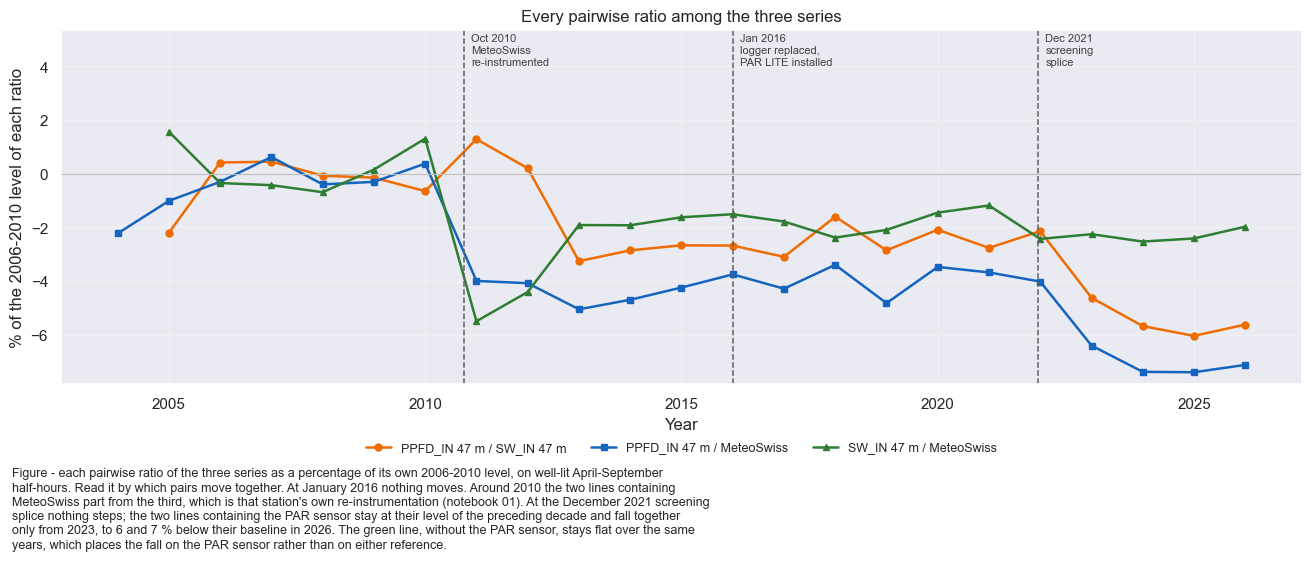

In [33]:
# The three ratios with the dates of this section marked: which changes are steps, which are
# drifts, and which pairs move together.
fig, ax = plt.subplots(figsize=(13, 5.5), dpi=100, layout="constrained")
for _label, _colour, _marker in [(f'{PPFD_47} / {SW_47}', '#EF6C00', 'o'),
                                 (f'{PPFD_47} / {MS_SW}', '#1565C0', 's'),
                                 (f'{SW_47} / {MS_SW}', '#2E7D32', '^')]:
    ax.plot(relative.index, relative[_label], color=_colour, lw=1.8, marker=_marker, ms=5,
            label=_label)
ax.axhline(0, color='#BDBDBD', lw=0.8)
ax.set_xlabel("Year")
ax.set_ylabel(f"% of the {BASELINE_YEARS[0]}-{BASELINE_YEARS[1]} level of each ratio")
ax.set_title("Every pairwise ratio among the three series")
ax.grid(alpha=0.3)

_lo, _hi = ax.get_ylim()
ax.set_ylim(_lo, _hi + 0.34 * (_hi - _lo))
_top = ax.get_ylim()[1]
for _x, _text in [(2010.75, 'Oct 2010\nMeteoSwiss\nre-instrumented'),
                  (BREAK_YEAR, f'Jan {BREAK_YEAR}\nlogger replaced,\nPAR LITE installed'),
                  (SCREENING_YEAR - 0.05, f'Dec {SCREENING_YEAR - 1}\nscreening\nsplice')]:
    ax.axvline(_x, color='#616161', lw=1.1, ls='--')
    ax.text(_x + 0.15, _top - 0.15, _text, fontsize=8, color='#424242', va='top')
ax.legend(fontsize=9, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.13), frameon=False)

_end_year = int(relative.index.max())
_end_fall = relative.loc[_end_year, PPFD_PAIRS].abs()
figcap(fig, f"each pairwise ratio of the three series as a percentage of its own "
            f"{BASELINE_YEARS[0]}-{BASELINE_YEARS[1]} level, on well-lit April-September "
            f"half-hours. Read it by which pairs move together. At January {BREAK_YEAR} nothing "
            f"moves. Around 2010 the two lines containing MeteoSwiss part from the third, which "
            f"is that station's own re-instrumentation (notebook 01). At the December "
            f"{SCREENING_YEAR - 1} screening splice nothing steps; the two lines containing the "
            f"PAR sensor stay at their level of the preceding decade and fall together only from "
            f"{SCREENING_YEAR + 1}, to {_end_fall.min():.0f} and {_end_fall.max():.0f} % below "
            f"their baseline in {_end_year}. The green line, without the PAR sensor, stays flat "
            f"over the same years, which places the fall on the PAR sensor rather than on either "
            f"reference.")

### 8️⃣ A fall in sensor response, 2022 to 2024

`PPFD_IN_T1_47_1` **declines relative to both radiation references**, by several per cent between
the 2022 and 2024 seasons. The 2022 season is not yet below 2021, so the decline first appears in
2023; it is measured from the 2021 level. It has not continued since 2024: 2025 and 2026 stay
within the ordinary one-year change of the 2024 level. The replacement of the tower box on 13 June
2023 does not explain it, since April and May 2023 already read low. This is a property of the
exported product, not of the gap-filling.

`RADIATION_SENSOR_CONTINUITY.ipynb` attributes it with four sensors: the two ratios containing this
sensor move, the ratio of the other two does not. This step reproduces the size of the decline on
this notebook's data and asserts it.

MeteoSwiss Lägern is another institution's instrument 2.5 km away. The tower `SW_IN` shares the
mast, logger and maintenance, but not the optics or calibration, where a response drift lives. A
decline against both is a change at this sensor.

#### 📋 Table: response of PPFD_IN by year

In [34]:
# The decline, measured with the same frame, controls and helper as the other steps. It has no
# date, so it is reported as a change over years rather than as a step.
DECLINE_FROM = 2021
response_rel = relative[PPFD_PAIRS]

tabcap(f"the response of PPFD_IN relative to each radiation reference, as a percentage of its own "
       f"{BASELINE_YEARS[0]}-{BASELINE_YEARS[1]} level. Only well-lit April-September half-hours "
       f"enter, as monthly medians averaged over months, so neither season nor sunniness moves a "
       f"row")
display(response_rel.round(2))

_last = int(response_rel.index.max())
_fall = response_rel.loc[_last] - response_rel.loc[DECLINE_FROM]
print(f"\nchange in the response of PPFD_IN from {DECLINE_FROM} to {_last}:")
for _o, _v in _fall.items():
    print(f"  {_o:<28s} {_v:+.2f} %   "
          f"(and {response_rel.loc[_last, _o]:+.2f} % against {BASELINE_YEARS[0]}-"
          f"{BASELINE_YEARS[1]})")

# Exported as measured, so this is a limitation, not a correction. The assertions keep it true in
# both directions: a reversal makes the text wrong, and a decline past 10 % needs a decision.
assert (_fall < -2.0).all(), (
    "PPFD_IN no longer falls against both references since 2021 - the limitation described here "
    "and on the documentation page must be re-derived rather than left in place")
assert (response_rel.loc[_last] > -10.0).all(), (
    "the decline has passed 10 % of the baseline response - it is no longer a limitation to note "
    "in passing and the product needs a decision rather than a paragraph")
_last_year_change = response_rel.loc[_last] - response_rel.loc[_last - 1]
print("\nThe decline is present against both references. Change over the last year of the "
      "record: " + ", ".join(f"{_o} {_v:+.2f} %" for _o, _v in _last_year_change.items()))

Table - the response of PPFD_IN relative to each radiation reference, as a percentage of its own
2006-2010 level. Only well-lit April-September half-hours enter, as monthly medians averaged over
months, so neither season nor sunniness moves a row



,PPFD_IN 47 m / SW_IN 47 m,PPFD_IN 47 m / MeteoSwiss
YEAR,,
2004,NaN,-2.23
2005,-2.20,-1.01
2006,0.42,-0.30
2007,0.45,0.62
2008,-0.07,-0.40
2009,-0.15,-0.30
2010,-0.65,0.38
2011,1.29,-4.00
2012,0.20,-4.08



change in the response of PPFD_IN from 2021 to 2026:
  PPFD_IN 47 m / SW_IN 47 m    -2.86 %   (and -5.63 % against 2006-2010)
  PPFD_IN 47 m / MeteoSwiss    -3.45 %   (and -7.13 % against 2006-2010)

The decline is present against both references. Change over the last year of the record: PPFD_IN 47 m / SW_IN 47 m +0.42 %, PPFD_IN 47 m / MeteoSwiss +0.27 %


#### 📊 Plot: response of PPFD_IN against two references

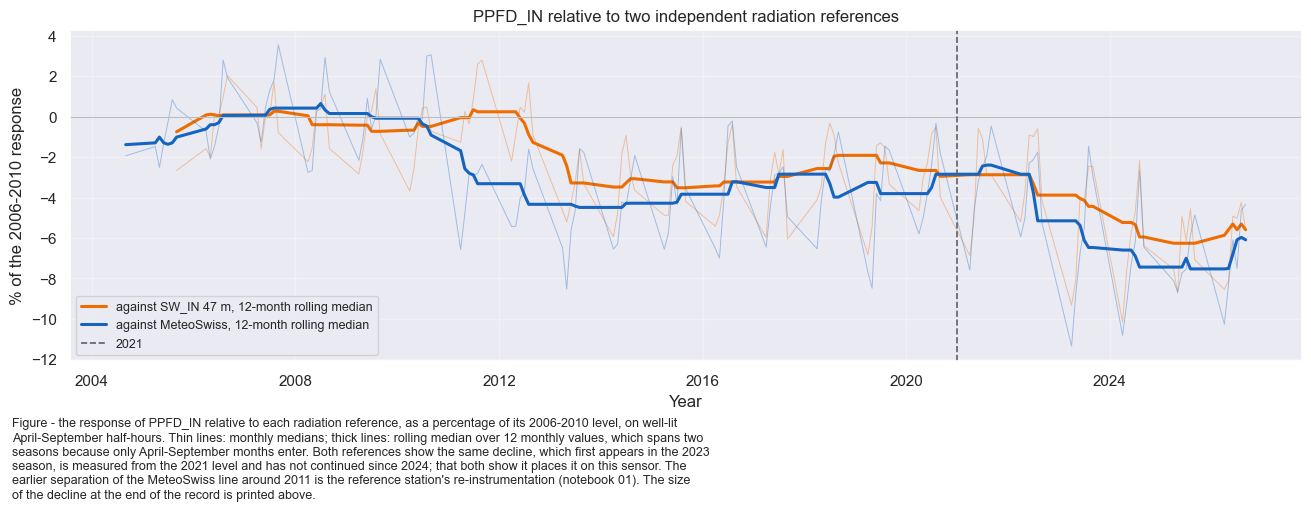

In [35]:
# Monthly medians behind a 12-month rolling median: a yearly table cannot show whether the drift
# has levelled off.
fig, ax = plt.subplots(figsize=(13, 5), dpi=100, layout="constrained")
for _o, _colour in [(SW_47, '#EF6C00'), (MS_SW, '#1565C0')]:
    _j = rad.loc[USABLE, [PPFD_47, _o]].dropna()
    _j = _j[(_j[PPFD_47] > MIN_IRRADIANCE) & (_j[_o] > MIN_IRRADIANCE)]
    _r = (_j[PPFD_47] / _j[_o])
    _monthly = _r.resample('MS').median()
    _monthly = _monthly[_r.resample('MS').count() >= 100]
    _rel = 100 * (_monthly / _monthly.loc[f'{BASELINE_YEARS[0]}':f'{BASELINE_YEARS[1]}'].median() - 1)
    ax.plot(_rel.index, _rel, color=_colour, lw=0.7, alpha=0.35)
    ax.plot(_rel.index, _rel.rolling(12, center=True, min_periods=6).median(), color=_colour,
            lw=2.2, label=f'against {_o}, 12-month rolling median')
ax.axhline(0, color='#BDBDBD', lw=0.8)
ax.axvline(pd.Timestamp(f'{DECLINE_FROM}-01-01'), color='#616161', lw=1.2, ls='--',
           label=f'{DECLINE_FROM}')
ax.set_xlabel("Year")
ax.set_ylabel(f"% of the {BASELINE_YEARS[0]}-{BASELINE_YEARS[1]} response")
ax.set_title("PPFD_IN relative to two independent radiation references")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='lower left')
figcap(fig, f"the response of PPFD_IN relative to each radiation reference, as a percentage of "
            f"its {BASELINE_YEARS[0]}-{BASELINE_YEARS[1]} level, on well-lit April-September "
            f"half-hours. Thin lines: monthly medians; thick lines: rolling median over 12 monthly "
            f"values, which spans two seasons because only April-September months enter. Both "
            f"references show the same decline, which first appears in the 2023 season, is "
            f"measured from the {DECLINE_FROM} level and has not continued since 2024; that both "
            f"show it places it on this sensor. The earlier "
            f"separation of the MeteoSwiss line around 2011 is the reference station's "
            f"re-instrumentation (notebook 01). The size of the decline at the end of the record "
            f"is printed above.")

::: {.callout-warning title="Known limitation of this product"}

`PPFD_IN_T1_47_1` is exported **as measured**, without correcting the decline. The decline has no
date at which to apply a correction, and no maintenance record names a cause, so a correction would
be a rescaling towards a reference rather than the repair of a known fault.

- A **trend** over the last years of the record, or across 2021, contains the sensor's decline as
  well as any change in the light (size in the table above).
- Comparisons **within** a year, and the relation of `PPFD_IN` to other radiation variables at a
  given time, are unaffected.
- Gap-filled records inherit the sensor's state at the time, because the model is trained on the
  surrounding measurements; they neither add nor remove the bias.

The likeliest cause, after more than twenty years in the field, is soiling or ageing of the
diffuser and detectors. A calibration or replacement would settle it.

:::

#### What this section settles

`PPFD_IN_T1_47_1` is **one instrument over the whole record**: the Delta-T sunshine sensor, at 47 m
since August 2004 and never replaced, read through the same conversion by both acquisition
systems. It is **homogeneous** across the January 2016 changeover and the December 2021 splice, so
no `_HOMOGENIZED` column is exported; the assertions above keep that claim true. The decline is
real, on this sensor, uncorrected, and the first thing the variable's documentation page states.

## 🟥 Gap-filling

### Method

diive has no `PPFD_IN` gap-filling class, so this uses `XGBoostTS` with an explicit
`FeatureEngineer`, as notebook `02` does for `TA`, with two radiation-specific settings:

- **`below_zero='zero'`**: negative predictions are clipped.
- **Nighttime gaps are set to zero** after modelling and flagged `3`, as `SWINGapFillerXGBoost`
  does in notebook `01`; a modelled value at night would be noise around a known answer.

As in `02`: no lag features (a lag of a gappy driver demotes records to the timestamp-only
fallback), `SW_IN_POT` excluded from the rolling and EMA stages (it is deterministic), SHAP capped
at 10,000 rows, and short daytime gaps interpolated and flagged `4`.

In [36]:
SHAP_MAX_ROWS = 10_000


def short_gap_mask(missing: pd.Series, limit: int) -> pd.Series:
    """True where `missing` is set AND its whole run is at most `limit` records long.

    Takes a boolean gap mask rather than the series itself, so the caller can pass the
    mask from before the nighttime offset correction.
    """
    run_length = missing.groupby((~missing).cumsum()).transform('sum')
    return missing & (run_length <= limit)


def gapfill_ppfd(target: pd.Series,
                 drivers: pd.DataFrame,
                 swinpot: pd.Series,
                 original_gaps: pd.Series,
                 interpolate_limit: int = 2,
                 reduce_features: bool = True,
                 verbose: int = 1):
    """Gap-fill PPFD with XGBoost, force nighttime to zero, interpolate short daytime gaps.

    `original_gaps` must be the gap mask from BEFORE the nighttime offset correction:
    that correction zeroes every nighttime record including the missing ones, so
    `target.isna()` here would report no nighttime gaps at all and label them as measured.

    Returns (model, gapfilled, flag).
    """
    daytime = swinpot >= NIGHTTIME_THRESHOLD

    input_df = pd.concat([target, drivers], axis=1)
    engineer = dv.gapfilling.FeatureEngineer(
        target_col=target.name,
        features_lag=[],
        features_rolling=[4, 8, 24, 48],
        features_rolling_stats=['median'],
        features_rolling_exclude_cols=['SW_IN_POT'],
        features_ema=[6, 24],
        features_ema_exclude_cols=['SW_IN_POT'],
        vectorize_timestamps=True,
        add_continuous_record_number=True,
        verbose=0,
    )
    features_df = engineer.fit_transform(input_df)
    print(f"Features: {features_df.shape[1] - 1} over {len(features_df):,} records")

    model = dv.gapfilling.XGBoostTS(
        input_df=features_df, target_col=target.name, verbose=verbose,
        below_zero='zero',           # photon flux cannot be negative
        shap_max_rows=SHAP_MAX_ROWS,
        n_estimators=3000, max_depth=6, early_stopping_rounds=20,
        random_state=42, n_jobs=-1,
    )
    model.trainmodel(showplot_scores=False, showplot_importance=False)
    if reduce_features:
        model.reduce_features()
        model.trainmodel(showplot_scores=False, showplot_importance=False)
    model.fillgaps(showplot_scores=False, showplot_importance=False)

    gapfilled = model.results.gapfilled.copy()
    flag = model.results.flag.copy()

    # Physics beats the model at night: no incoming PAR after sunset.
    night_gaps = original_gaps & ~daytime
    gapfilled[night_gaps] = 0.0
    flag[night_gaps] = 3
    print(f"Nighttime gaps set to 0: {int(night_gaps.sum()):,}")

    # Short DAYTIME gaps only - a night is already handled above. The run-length search
    # uses the pre-correction mask for the same reason as above.
    if interpolate_limit:
        short = short_gap_mask(original_gaps, interpolate_limit) & daytime
        interp = target.interpolate(method='time', limit_area='inside')
        fill_locs = short & interp.notna()
        gapfilled[fill_locs] = interp[fill_locs]
        flag[fill_locs] = 4
        print(f"Short-gap interpolation: {int(fill_locs.sum())} records")

    gapfilled = gapfilled.rename(f"{target.name}_gfXG")
    flag = flag.rename(f"FLAG_{target.name}_ISFILLED")
    return model, gapfilled, flag

### Run gap-filling

In [37]:
%%time

gf_ppfd, gapfilled_ppfd, flag_ppfd = gapfill_ppfd(
    target=ppfd_2004_2026[TARGET],
    drivers=drivers,
    swinpot=drivers['SW_IN_POT'],
    original_gaps=PPFD_ORIGINAL_GAPS,  # from BEFORE the offset correction, see there
)

Features: 46 over 398,832 records


! Some features are incomplete (<398832 values): SW_IN_LAE_MS (397230), .SW_IN_LAE_MS_MEAN4 
(397265), .SW_IN_LAE_MS_SD4 (397265), .SW_IN_LAE_MS_MEAN8 (397290), .SW_IN_LAE_MS_SD8 (397290), 
.SW_IN_LAE_MS_MEAN24 (397336), .SW_IN_LAE_MS_SD24 (397336), .SW_IN_LAE_MS_MEAN48 (397343), 
.SW_IN_LAE_MS_SD48 (397343), .SW_IN_LAE_MS_ROLLMEDIAN4 (397265), .SW_IN_LAE_MS_ROLLMEDIAN8 (397290),
.SW_IN_LAE_MS_ROLLMEDIAN24 (397336), .SW_IN_LAE_MS_ROLLMEDIAN48 (397343), .SW_IN_LAE_MS_EMA6 
(397343), .SW_IN_LAE_MS_EMA24 (397343)

! Not all target values can be predicted based on the full model.

Nighttime gaps set to 0: 7,543
Short-gap interpolation: 87 records
CPU times: total: 32min 31s
Wall time: 2min 32s


### Results: scores and feature importances

#### 📋 Table: held-out scores

In [38]:
tabcap("held-out scores of the gap-filling model as diive reports them, computed on records not "
       "used in training")
display(pd.Series(gf_ppfd.results.scores_traintest))

Table - held-out scores of the gap-filling model as diive reports them, computed on records not used
in training



mae      8.456275e+00
medae    1.464546e+00
mse      5.126151e+02
rmse     2.264101e+01
mape     1.547214e+15
maxe     1.255865e+03
r2       9.978513e-01
dtype: float64

#### 📋 Table: records per provenance code

In [39]:
tabcap("records per provenance code, before the export checks repeat the count on the finished "
       "frame")
display(flag_ppfd.value_counts().sort_index().rename(index=FLAG_LEGEND))

Table - records per provenance code, before the export checks repeat the count on the finished frame



FLAG_PPFD_IN_T1_47_1_ISFILLED
0 = observed                                                                  382228
1 = gap-filled by the XGBoost model                                             8374
2 = gap-filled by the timestamp-only fallback model (a driver was missing)       600
3 = nighttime gap, set to zero by physics                                       7543
4 = gap-filled by linear interpolation (short gap)                                87
Name: count, dtype: int64

#### 📋 Table: driver importance

In [40]:
tabcap("driver importance for the PPFD_IN_T1_47_1 model, as the gap-filler reports it")
display(gf_ppfd.results.feature_importances)

Table - driver importance for the PPFD_IN_T1_47_1 model, as the gap-filler reports it



,SHAP_IMPORTANCE,SHAP_SD
SW_IN_T1_47_1_gfXG,298.368927,246.504822
SW_IN_LAE_MS,57.744114,71.532425
SW_IN_POT,15.595906,7.421626
.SW_IN_T1_47_1_gfXG_MEAN48,7.029447,6.423215
.SW_IN_LAE_MS_SD48,6.533268,4.969448
...,...,...
.WEEK_SIN,1.030021,1.139976
.SW_IN_LAE_MS_SD4,1.022837,1.337351
.SW_IN_T1_47_1_gfXG_MEAN24,1.012602,1.199659
.SW_IN_LAE_MS_MEAN24,0.941819,1.016429


#### 📊 Plot: driver importance

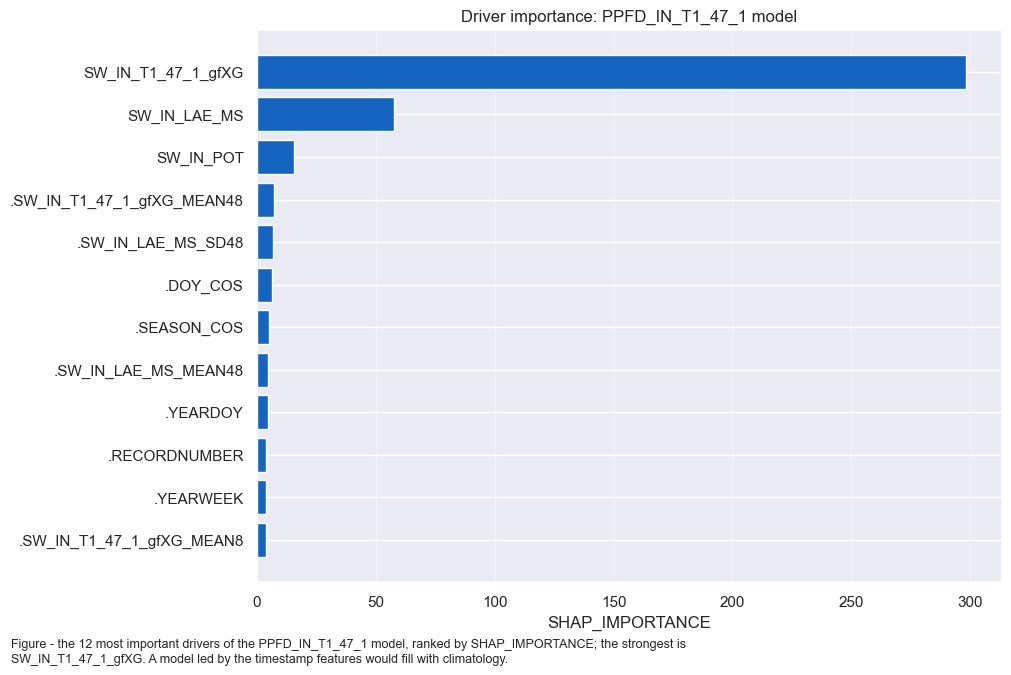

In [41]:
plot_feature_importances(gf_ppfd.results, label="PPFD_IN_T1_47_1 model");

#### 📊 Plot: measured, gap-filled and the fills alone

The bottom panel shows the filled values alone.

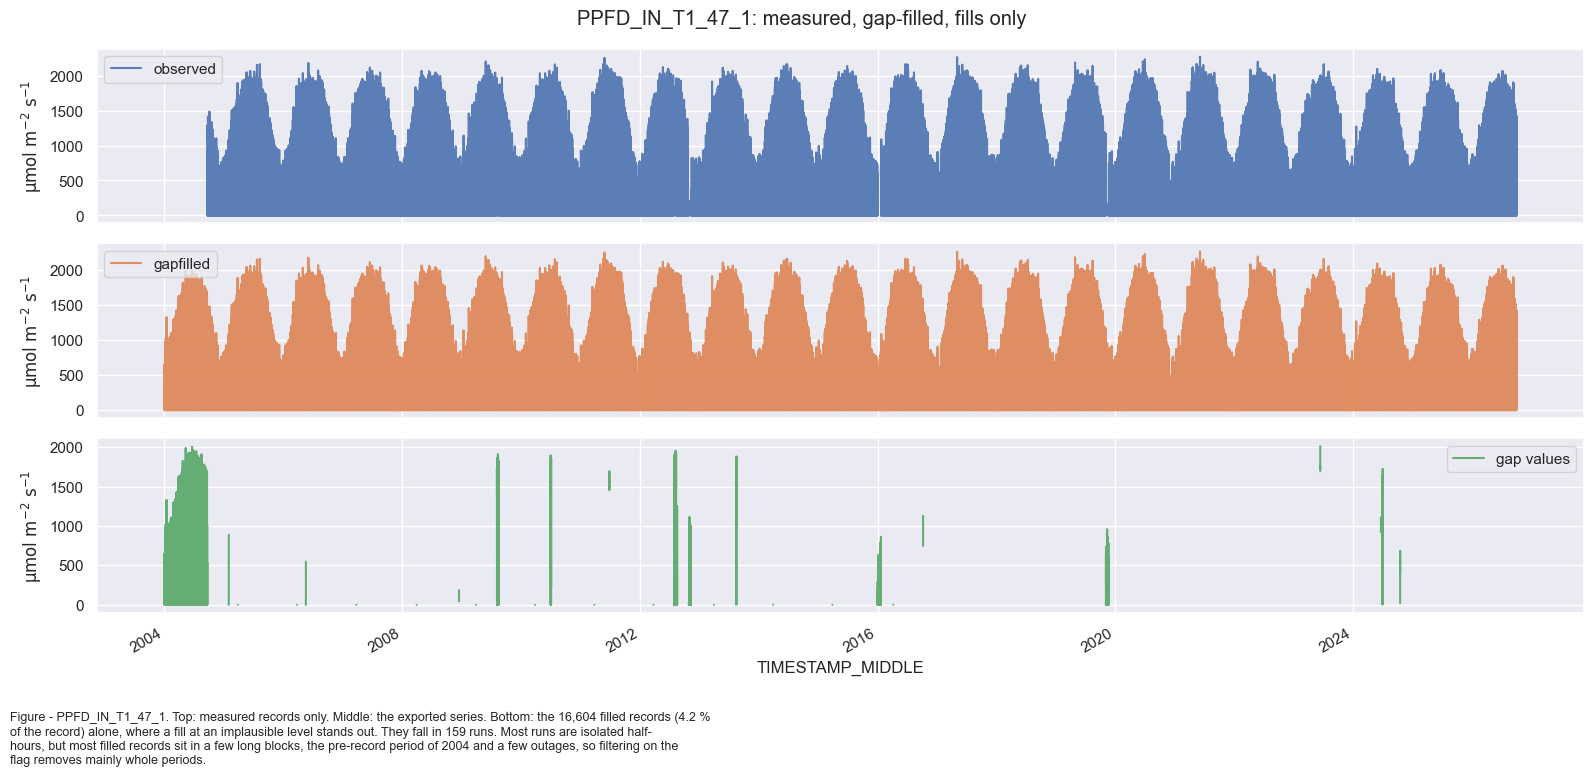

In [42]:
plot_gapfill_panels(gapfilled_ppfd, flag_ppfd, label=f"{TARGET}");

#### 📊 Plot: predicted against measured on held-out data

These records were not used in training.

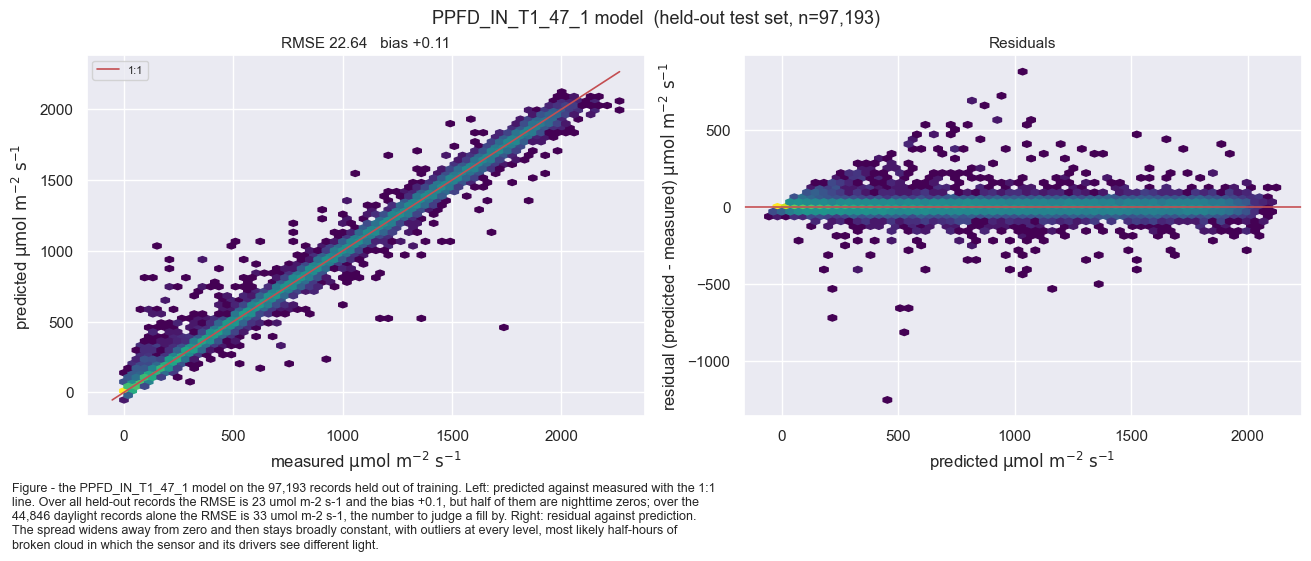

In [43]:
plot_pred_vs_measured(gf_ppfd, label=f"{TARGET} model");

***

## ➡️ Prepare dataframe for export

### 📋 Table: the exported frame

In [44]:
VALCOL = f"{TARGET}_gfXG"
FLAGCOL = f"FLAG_{TARGET}_ISFILLED"

export_df = pd.concat([gapfilled_ppfd, flag_ppfd], axis=1)
tabcap("the frame that is exported: the gap-filled series and the provenance code that travels with it")
export_df

Table - the frame that is exported: the gap-filled series and the provenance code that travels with
it



,PPFD_IN_T1_47_1_gfXG,FLAG_PPFD_IN_T1_47_1_ISFILLED
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,0.0,3
2004-01-01 00:45:00,0.0,3
2004-01-01 01:15:00,0.0,3
2004-01-01 01:45:00,0.0,3
2004-01-01 02:15:00,0.0,3
...,...,...
2026-09-30 21:45:00,0.0,0
2026-09-30 22:15:00,0.0,0
2026-09-30 22:45:00,0.0,0


Sanity check: complete, non-negative, a continuous 30MIN index without duplicates, the last record
at `PERIOD_END`, and a flag on every record. The flag separates measured from filled records
downstream.

### 📋 Table: provenance of the exported records

In [45]:
print(f"Records:         {len(export_df)}")
print(f"Missing values:  {export_df[VALCOL].isnull().sum()}")
print(f"Negative values: {(export_df[VALCOL] < 0).sum()}")
print(f"Missing flags:   {export_df[FLAGCOL].isnull().sum()}")
print(f"Duplicate index: {export_df.index.duplicated().sum()}")
print(f"Index gaps:      {(export_df.index.to_series().diff().dropna() != pd.Timedelta('30min')).sum()}")
print(f"Min / max:       {export_df[VALCOL].min():.2f} / {export_df[VALCOL].max():.2f}")
print(f"Last record:     {export_df.index[-1]}")
assert export_df.index[-1] == pd.Timestamp(PERIOD_END), (
    f"the export ends at {export_df.index[-1]}, not at PERIOD_END ({PERIOD_END})")

tabcap("provenance of every record in the exported product. Code 3 is a nighttime gap set to "
       "zero by physics, not an estimate, so codes 0 and 3 together are the share no model produced")
_counts = export_df[FLAGCOL].value_counts().sort_index()
display(pd.DataFrame({'count': _counts,
                      '%': (100 * _counts / len(export_df)).round(2)}).rename(index=FLAG_LEGEND))
print(f"Measured: {100 * (export_df[FLAGCOL] == 0).mean():.2f}%  |  "
      f"Filled: {100 * (export_df[FLAGCOL] > 0).mean():.2f}%")

Records:         398832
Missing values:  0
Negative values: 0
Missing flags:   0
Duplicate index: 0
Index gaps:      0
Min / max:       0.00 / 2271.09
Last record:     2026-09-30 23:45:00
Table - provenance of every record in the exported product. Code 3 is a nighttime gap set to zero by
physics, not an estimate, so codes 0 and 3 together are the share no model produced



,count,%
FLAG_PPFD_IN_T1_47_1_ISFILLED,,
0 = observed,382228,95.84
1 = gap-filled by the XGBoost model,8374,2.10
2 = gap-filled by the timestamp-only fallback model (a driver was missing),600,0.15
"3 = nighttime gap, set to zero by physics",7543,1.89
4 = gap-filled by linear interpolation (short gap),87,0.02


Measured: 95.84%  |  Filled: 4.16%


### 📋 Table: summary statistics of the export

In [46]:
tabcap("summary statistics of the exported product")
export_df.describe()

Table - summary statistics of the exported product



,PPFD_IN_T1_47_1_gfXG,FLAG_PPFD_IN_T1_47_1_ISFILLED
count,398832.000000,398832.000000
mean,295.170770,0.081616
std,491.181362,0.440520
min,0.000000,0.000000
25%,0.000000,0.000000
50%,7.006331,0.000000
75%,387.221537,0.000000
max,2271.086339,4.000000


### 📊 📋 Plot and table: filled records per year

**2004.** Measurements start on 20 September 2004. Earlier records are modelled from the `SW_IN` of
notebook `01`, which is itself reconstructed for 2004 from NABEL: a fill built on a fill, marked by
the flag. 2026 is a partial year (January to September).

Table - records per year and provenance code for PPFD_IN_T1_47_1_gfXG; each row sums to the half-
hours of that year; 2026 is a partial year (January to September)



,0 = observed,1 = gap-filled by the XGBoost model,2 = gap-filled by the timestamp-only fallback model (a driver was missing),"3 = nighttime gap, set to zero by physics",4 = gap-filled by linear interpolation (short gap)
year,,,,,
2004,4922,6518,571,5556,1
2005,17485,10,0,17,8
2006,17493,5,0,14,8
2007,17507,0,0,6,7
2008,17548,4,0,8,8
2009,17036,292,0,184,8
2010,17351,109,0,55,5
2011,17499,10,0,6,5
2012,16310,627,29,596,6


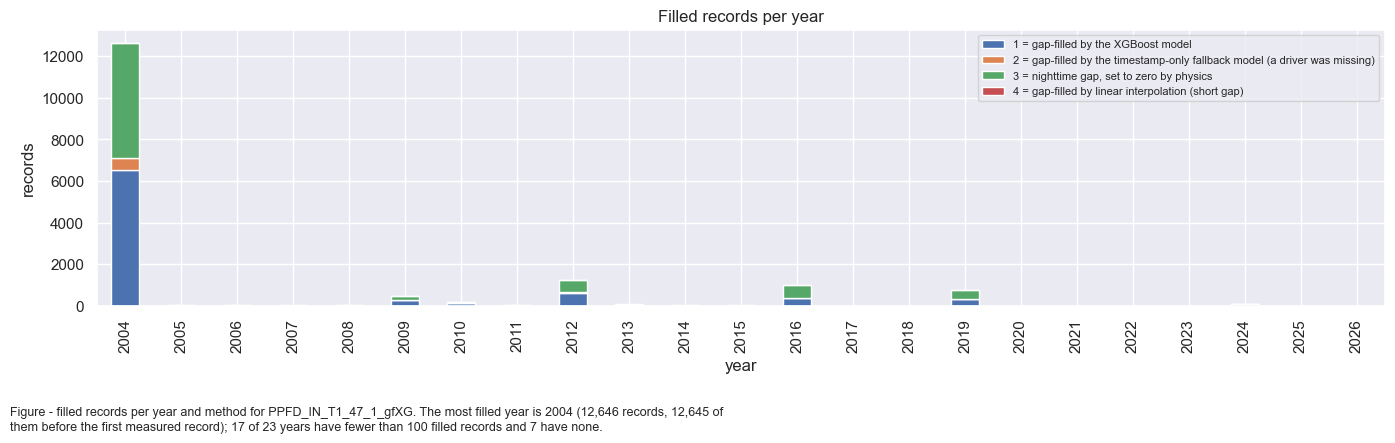

In [47]:
fill_stats_by_year(export_df[FLAGCOL], label=VALCOL)

### 📊 Plot: gap-filling overview

Where the fills sit and whether they behave like measurements. In the monthly means the two lines
should track each other.

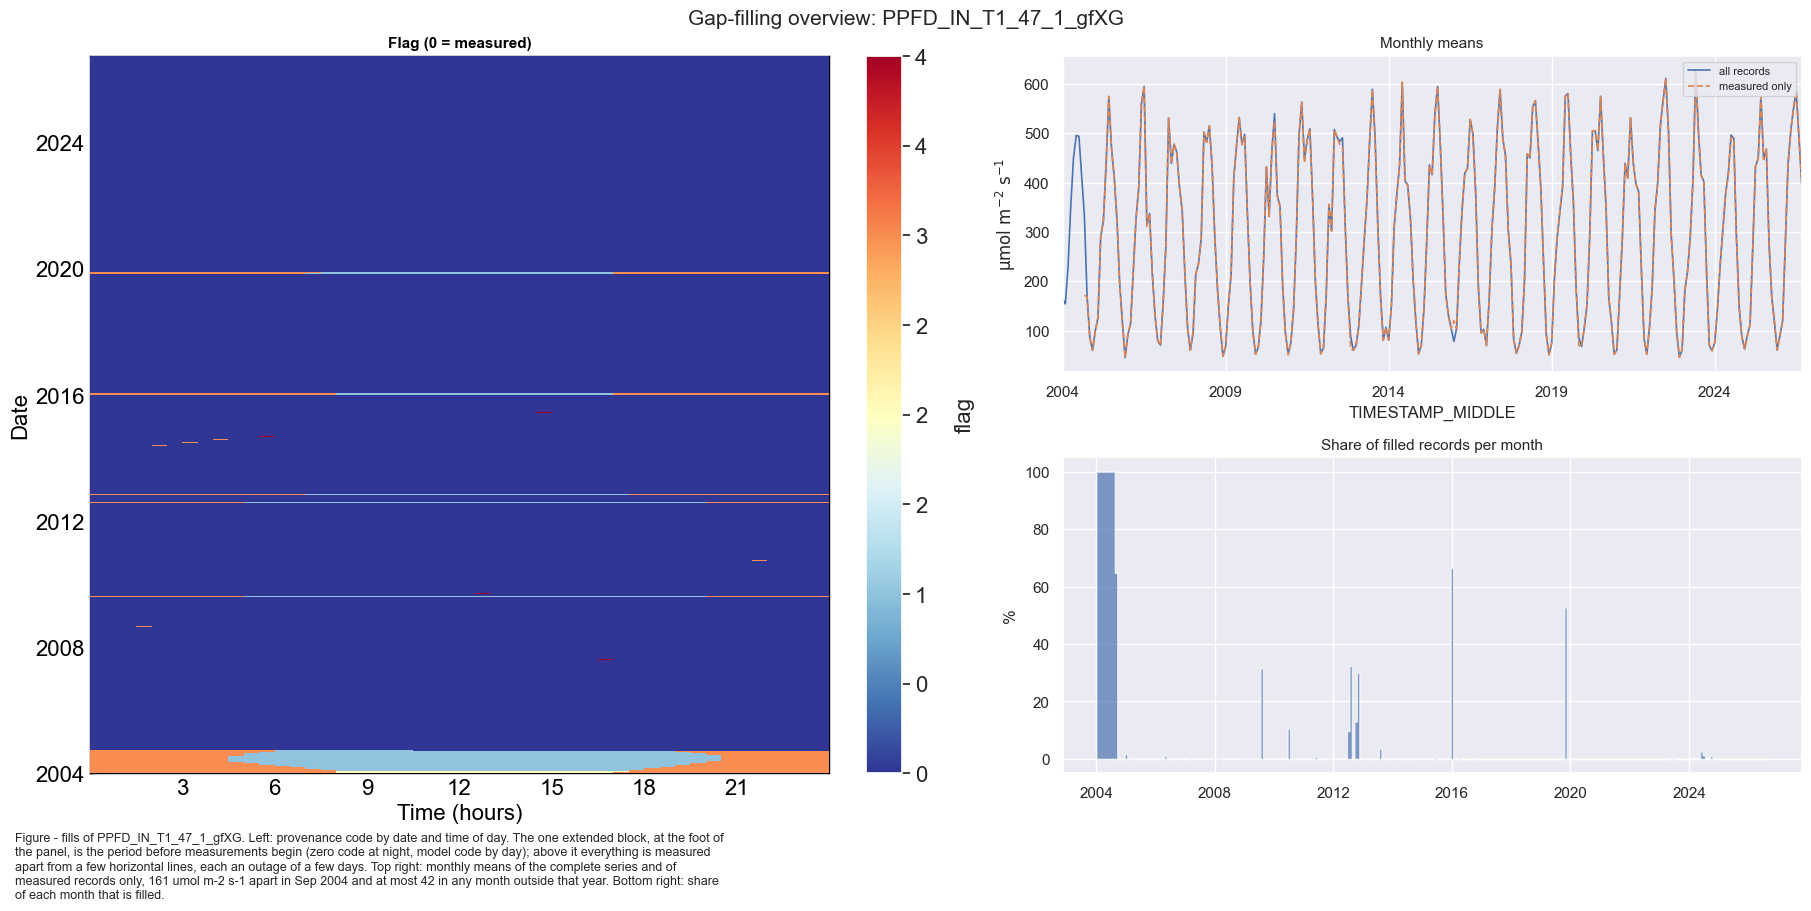

In [48]:
plot_fill_overview(export_df[VALCOL], export_df[FLAGCOL], label=VALCOL);

### 📊 Plot: heatmap of the exported product

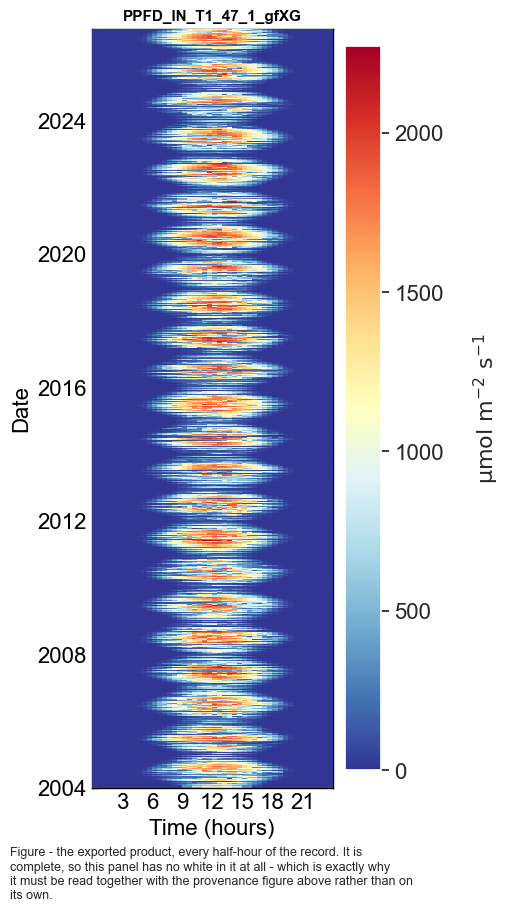

In [49]:
fig, ax = plt.subplots(figsize=(5, 9), dpi=100, layout="constrained")
dv.plotting.HeatmapDateTime(series=export_df[VALCOL]).plot(
    ax=ax, cb_digits_after_comma=0, zlabel=r'$\mathrm{\mu mol\ m^{-2}\ s^{-1}}$',
    format_style=dv.plotting.FormatStyle(title=VALCOL, title_fontsize=11))
figcap(fig, "the exported product, every half-hour of the record. It is complete, so this "
            "panel has no white in it at all - which is exactly why it must be read "
            "together with the provenance figure above rather than on its own.")

### The exported product

The average day through the year, physical plausibility, and the *spread* of filled against
measured records: a fill with the right mean and no weather in it passes a level test and fails
the spread test. Annual means use full years only (up to `LAST_FULL_YEAR`).

#### 📊 Plot: mean daily cycle and annual means

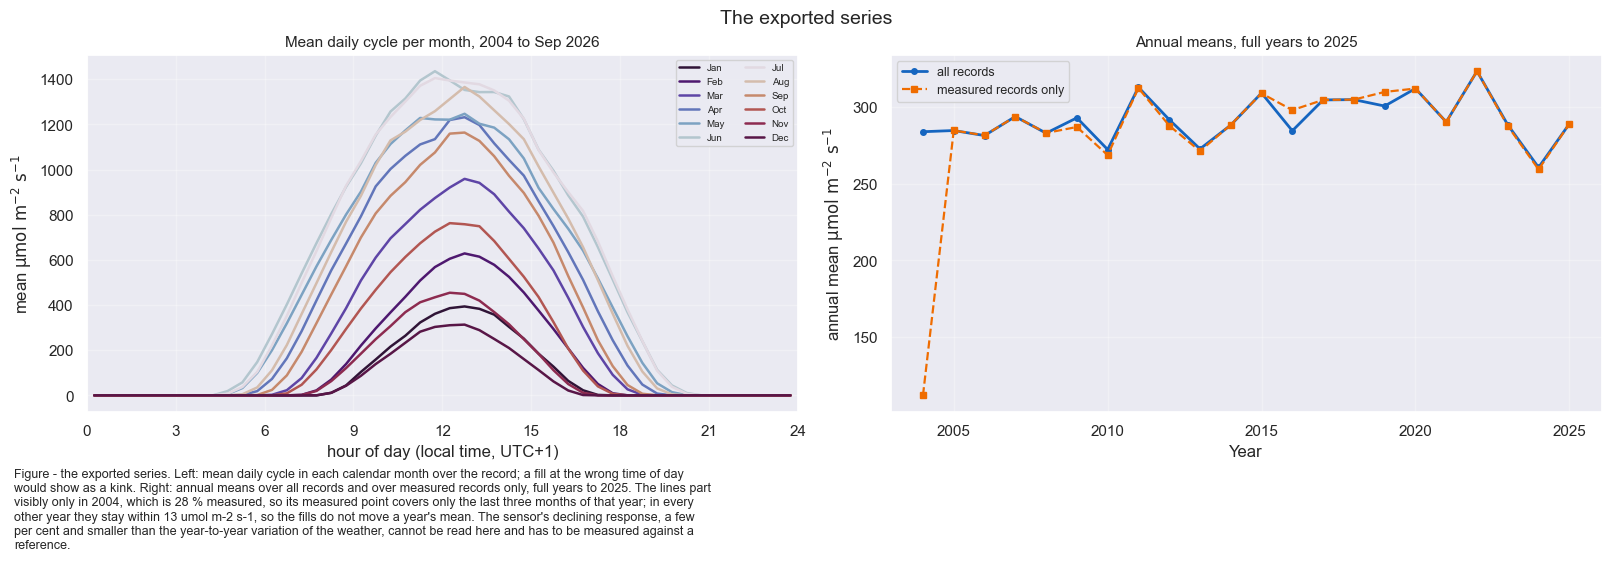

In [50]:
# The average day per month and the annual means: a fill at the wrong time of day would distort
# the first.
_pot_out = dv.variables.potrad(timestamp_index=export_df.index, lat=SITE_LAT, lon=SITE_LON,
                               utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
_d = pd.DataFrame({'v': export_df[VALCOL], 'flag': export_df[FLAGCOL], 'pot': _pot_out})
_d['hour'] = _d.index.hour + _d.index.minute / 60
_d['month'] = _d.index.month

fig, axs = plt.subplots(ncols=2, figsize=(16, 5.5), dpi=100, layout='constrained')
fig.suptitle('The exported series', fontsize=14)

_comp = _d.pivot_table(index='hour', columns='month', values='v', aggfunc='mean')
_cmap = plt.get_cmap('twilight_shifted')
for _m in _comp.columns:
    axs[0].plot(_comp.index, _comp[_m], color=_cmap((_m - 1) / 12), lw=1.8,
                label=pd.Timestamp(2020, _m, 1).strftime('%b'))
axs[0].set_xlabel('hour of day (local time, UTC+1)')
axs[0].set_ylabel(r'mean $\mathrm{\mu mol\ m^{-2}\ s^{-1}}$')
axs[0].set_xlim(0, 24)
axs[0].set_xticks(range(0, 25, 3))
axs[0].set_title(f'Mean daily cycle per month, 2004 to {pd.Timestamp(PERIOD_END):%b %Y}',
                 fontsize=11)
axs[0].grid(alpha=0.3)
axs[0].legend(fontsize=7, ncol=2)

_ann = _d['v'].resample('YE').mean()
_ann.index = _ann.index.year
_ann_meas = _d['v'].where(_d['flag'] == 0).resample('YE').mean()
_ann_meas.index = _ann_meas.index.year
# Full years only: a January-September mean is not comparable with a calendar-year mean
_ann = _ann.loc[:LAST_FULL_YEAR]
_ann_meas = _ann_meas.loc[:LAST_FULL_YEAR]
axs[1].plot(_ann.index, _ann, color='#1565C0', lw=2, marker='o', ms=4, label='all records')
axs[1].plot(_ann_meas.index, _ann_meas, color='#EF6C00', lw=1.6, ls='--', marker='s', ms=4,
            label='measured records only')
axs[1].set_xlabel('Year')
axs[1].set_ylabel(r'annual mean $\mathrm{\mu mol\ m^{-2}\ s^{-1}}$')
axs[1].set_title(f'Annual means, full years to {LAST_FULL_YEAR}', fontsize=11)
axs[1].grid(alpha=0.3)
axs[1].legend(fontsize=9)

_meas_share_2004 = 100 * (_d.loc['2004', 'flag'] == 0).mean()
_ann_gap = (_ann - _ann_meas).abs().drop(index=2004).max()
figcap(fig, f"the exported series. Left: mean daily cycle in each calendar month over the "
            f"record; a fill at the wrong time of day would show as a kink. Right: annual means "
            f"over all records and over measured records only, full years to {LAST_FULL_YEAR}. "
            f"The lines part visibly only in 2004, which is {_meas_share_2004:.0f} % measured, "
            f"so its measured point covers only the last three months of that year; in every "
            f"other year they stay within {_ann_gap:.0f} umol m-2 s-1, so the fills do not move "
            f"a year's mean. The sensor's declining response, a few per cent and smaller than the "
            f"year-to-year variation of the weather, cannot be read here and has to be measured "
            f"against a reference.")

#### 📊 Plot: physical plausibility

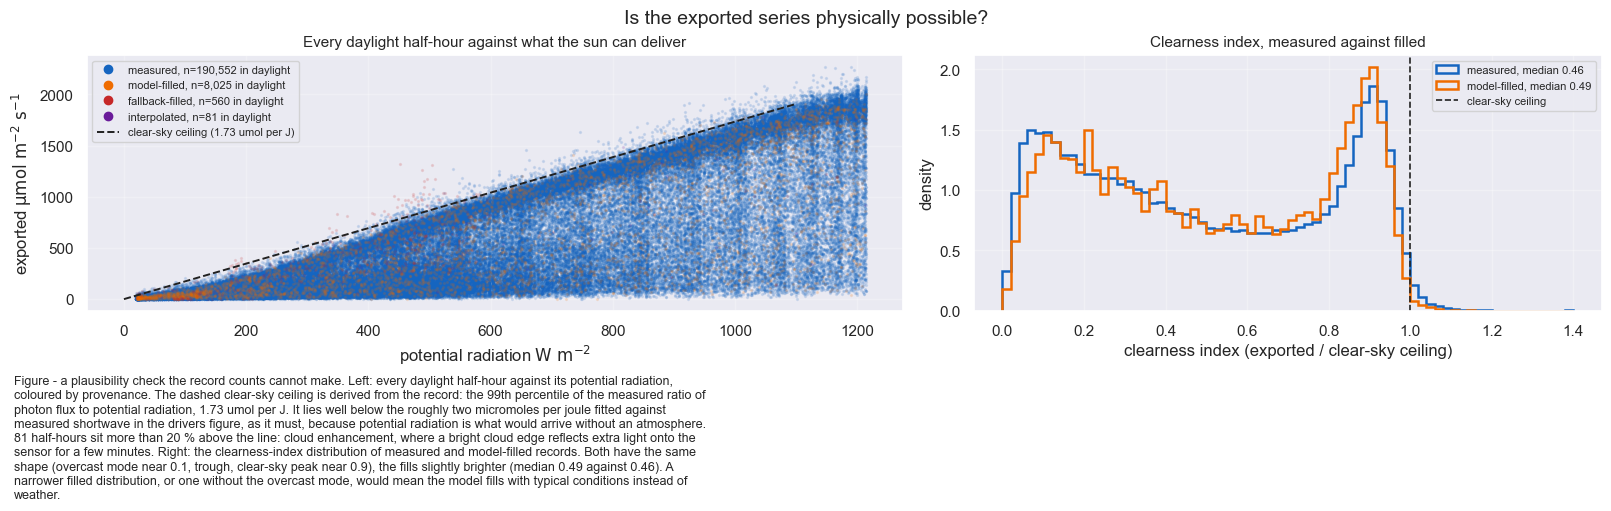

In [51]:
# Plausibility and spread. Photon flux and potential radiation differ in unit, so the ceiling is
# not the 1:1 line of notebook 01 but a photon-to-energy ratio derived from the clear-sky records.
_lit = _d[_d['pot'] > 20]
CLEAR = _lit[(_lit['flag'] == 0) & (_lit['v'] / _lit['pot'] > 0)]
PHOTON_RATIO = float((CLEAR['v'] / CLEAR['pot']).quantile(0.99))   # umol per J of shortwave
_kt = (_d['v'] / (_d['pot'] * PHOTON_RATIO)).where(_d['pot'] > 20)

fig, axs = plt.subplots(ncols=2, figsize=(16, 5), dpi=100, layout='constrained',
                        width_ratios=[1.3, 1])
fig.suptitle('Is the exported series physically possible?', fontsize=14)

_sample = _lit.sample(min(120_000, len(_lit)), random_state=42)
for _flagval, _colour, _lab in [(0, '#1565C0', 'measured'), (1, '#EF6C00', 'model-filled'),
                                (2, '#C62828', 'fallback-filled'),
                                (4, '#6A1B9A', 'interpolated')]:
    _s = _sample[_sample['flag'] == _flagval]
    if len(_s):
        axs[0].scatter(_s['pot'], _s['v'], s=2, alpha=0.12, color=_colour, rasterized=True)
        axs[0].plot([], [], 'o', color=_colour,
                    label=f'{_lab}, n={int((_lit["flag"] == _flagval).sum()):,} in daylight')
axs[0].plot([0, 1100], [0, 1100 * PHOTON_RATIO], color='#212121', lw=1.4, ls='--',
            label=f'clear-sky ceiling ({PHOTON_RATIO:.2f} umol per J)')
axs[0].set_xlabel(r'potential radiation $\mathrm{W\ m^{-2}}$')
axs[0].set_ylabel(r'exported $\mathrm{\mu mol\ m^{-2}\ s^{-1}}$')
axs[0].set_title('Every daylight half-hour against what the sun can deliver', fontsize=11)
axs[0].legend(fontsize=8, loc='upper left')
axs[0].grid(alpha=0.25)

for _flagval, _colour, _lab in [(0, '#1565C0', 'measured'), (1, '#EF6C00', 'model-filled')]:
    _s = _kt[_d['flag'] == _flagval].dropna()
    if len(_s):
        axs[1].hist(_s.clip(0, 1.4), bins=np.linspace(0, 1.4, 71), histtype='step', lw=1.8,
                    density=True, color=_colour, label=f'{_lab}, median {_s.median():.2f}')
axs[1].axvline(1.0, color='#212121', lw=1.2, ls='--', label='clear-sky ceiling')
axs[1].set_xlabel('clearness index (exported / clear-sky ceiling)')
axs[1].set_ylabel('density')
axs[1].set_title('Clearness index, measured against filled', fontsize=11)
axs[1].legend(fontsize=8)
axs[1].grid(alpha=0.3)

_over = int((_kt > 1.2).sum())
_kt_meas = _kt[_d['flag'] == 0].dropna()
_kt_fill = _kt[_d['flag'] == 1].dropna()
figcap(fig, f"a plausibility check the record counts cannot make. Left: every daylight half-hour "
            f"against its potential radiation, coloured by provenance. The dashed clear-sky "
            f"ceiling is derived from the record: the 99th percentile of the measured ratio of "
            f"photon flux to potential radiation, {PHOTON_RATIO:.2f} umol per J. It lies well "
            f"below the roughly two micromoles per joule fitted against measured shortwave in the "
            f"drivers figure, as it must, because potential radiation is what would arrive without "
            f"an atmosphere. {_over:,} half-hours sit more than 20 % above the line: cloud "
            f"enhancement, where a bright cloud edge reflects extra light onto the sensor for a "
            f"few minutes. Right: the clearness-index distribution of measured and model-filled "
            f"records. Both have the same shape (overcast mode near 0.1, trough, clear-sky peak "
            f"near 0.9), the fills slightly brighter (median {_kt_fill.median():.2f} against "
            f"{_kt_meas.median():.2f}). A narrower filled distribution, or one without the "
            f"overcast mode, would mean the model fills with typical conditions instead of "
            f"weather.")

***

## 💾 Save to file

In [52]:
filepath = dv.save_parquet(filename=OUTNAME, data=export_df, outpath=OUTPATH)
export_df.to_csv(Path(OUTPATH) / f"{OUTNAME}.csv")
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\03_METEO_PPFD_IN_GAPFILLED_2004-2026.09.parquet (0.054 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\03_METEO_PPFD_IN_GAPFILLED_2004-2026.09.parquet


### Verify the written file

Reads the parquet back and checks the file itself, not the in-memory frame.

#### 📋 Table: yearly median and measured share, from the written file

In [53]:
_written = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"columns:   {list(_written.columns)}")
print(f"index:     {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"measured:  {int((_written[FLAGCOL] == 0).sum()):,} "
      f"({100 * (_written[FLAGCOL] == 0).mean():.2f}%)")
print(f"median:    {float(_written[VALCOL].median()):.3f} umol m-2 s-1")
print(f"min / max: {float(_written[VALCOL].min()):.3f} / {float(_written[VALCOL].max()):.3f} umol m-2 s-1")

assert list(_written.columns) == [VALCOL, FLAGCOL], "unexpected columns in the written file"
assert len(_written) == len(export_df), "record count changed on write"
assert _written.index.equals(export_df.index), "index changed on write"
# The product is documented as complete and non-negative; both claims are checked on the file.
assert _written[VALCOL].notna().all(), "the written file has gaps, but this product is exported complete"
assert float(_written[VALCOL].min()) >= 0, "negative photon flux in the written file"
assert float(_written[VALCOL].max()) < 3000, "photon flux above anything this latitude can deliver"
assert (set(_written[FLAGCOL].unique()) <= set(FLAG_LEGEND)), (
    "the written file carries a flag code that FLAG_LEGEND does not document")
print()
print("Written file verified.")

tabcap(f"yearly median and measured share of the column as written to the parquet file, read "
       f"back from disk. {LAST_FULL_YEAR + 1} is a partial year (January to "
       f"{pd.Timestamp(PERIOD_END):%B}), and its median is high only because it lacks the long "
       f"nights of October to December")
display(pd.DataFrame({
    'yearly median (umol m-2 s-1)': _written[VALCOL].groupby(_written.index.year).median().round(3),
    'measured (%)': (100 * (_written[FLAGCOL] == 0)).groupby(_written.index.year).mean().round(1),
}))

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\03_METEO_PPFD_IN_GAPFILLED_2004-2026.09.parquet (0.014 seconds).

columns:   ['PPFD_IN_T1_47_1_gfXG', 'FLAG_PPFD_IN_T1_47_1_ISFILLED']
index:     2004-01-01 00:15:00 -> 2026-09-30 23:45:00  (398,832 records)
measured:  382,228 (95.84%)
median:    7.006 umol m-2 s-1
min / max: 0.000 / 2271.086 umol m-2 s-1

Written file verified.
Table - yearly median and measured share of the column as written to the parquet file, read back
from disk. 2026 is a partial year (January to September), and its median is high only because it
lacks the long nights of October to December



,yearly median (umol m-2 s-1),measured (%)
TIMESTAMP_MIDDLE,,
2004,7.932,28.0
2005,7.216,99.8
2006,7.464,99.8
2007,7.085,99.9
2008,7.010,99.9
2009,6.395,97.2
2010,5.976,99.0
2011,6.066,99.9
2012,5.394,92.8


***

## End of notebook.

In [54]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-23 12:37:38
Finished: 2026-10-23 12:40:57
Runtime:  00:03:18 (hh:mm:ss)
